# Assistent immobiliari basat en regles

Aquest notebook conté el sistema de diàleg final de la Tasca 1 (TVD, pràctica P1). Correspon al resultat de l'exercici 7 després de dues iteracions de millora.

| Secció | Contingut |
|---|---|
| 0 | Objectius, arquitectura i diagrama del torn |
| 1 | Configuració i càrrega del JSON |
| 2 | Lèxic |
| 3 | Processament de l'entrada |
| 4 | Cerca de pisos |
| 5 | Gestor del diàleg (estat i política) |
| 6 | Microplanificació (què es diu) |
| 7 | Realització (com es diu) |
| 8 | Execució |
| 9 | Proves (72 proves automàtiques, linter gramatical i robustesa) |
| 10 | Diàlegs d'exemple i diàleg interactiu |

## 0. Objectius i arquitectura

**Objectius de disseny**
1. **Diàleg guiat per l'assistent, amb llibertat per a l'usuari** (iniciativa mixta). El sistema comença amb una pregunta oberta i després fa preguntes individuals per completar el que falta. En qualsevol torn, l'usuari pot donar, corregir o deixar com a indiferent qualsevol criteri, i també preguntar per un pis concret.
2. **Entendre bé l'usuari**: faltes d'ortografia; català, castellà o anglès; números en lletres; operadors i intervals; diverses dades en una mateixa frase.
3. **Política dinàmica**: a cada torn es recalculen els pisos candidats i la pregunta següent s'hi adapta.
   * No es pregunta el que tots els candidats comparteixen.
   * S'avisa al moment si no en queda cap i es proposa el canvi mínim que donaria resultats.
   * Amb pocs candidats, s'ofereix ensenyar-los.
4. **Generació clara i correcta**: es diu només la informació necessària, en català natural, amb connectors adequats i sense errors de combinació de plantilles.
5. **Robustesa**: el programa no s'atura amb cap entrada, i cada problema es recupera amb un missatge específic.

**Arquitectura.** Cada torn té tres passos:
1. **Processament de l'entrada** (`interpret`): de la frase a una representació semàntica.
2. **Gestor del diàleg** (`HouseBot.turn`): actualitza l'estat, aplica la política i, amb la **microplanificació**, decideix *què* es diu. El resultat és una llista d'unitats de contingut, sense text.
3. **Realització** (`realize`): decideix *com* es diu, és a dir, converteix les unitats en frases.

El diagrama mostra l'ordre de les comprovacions dins del gestor.

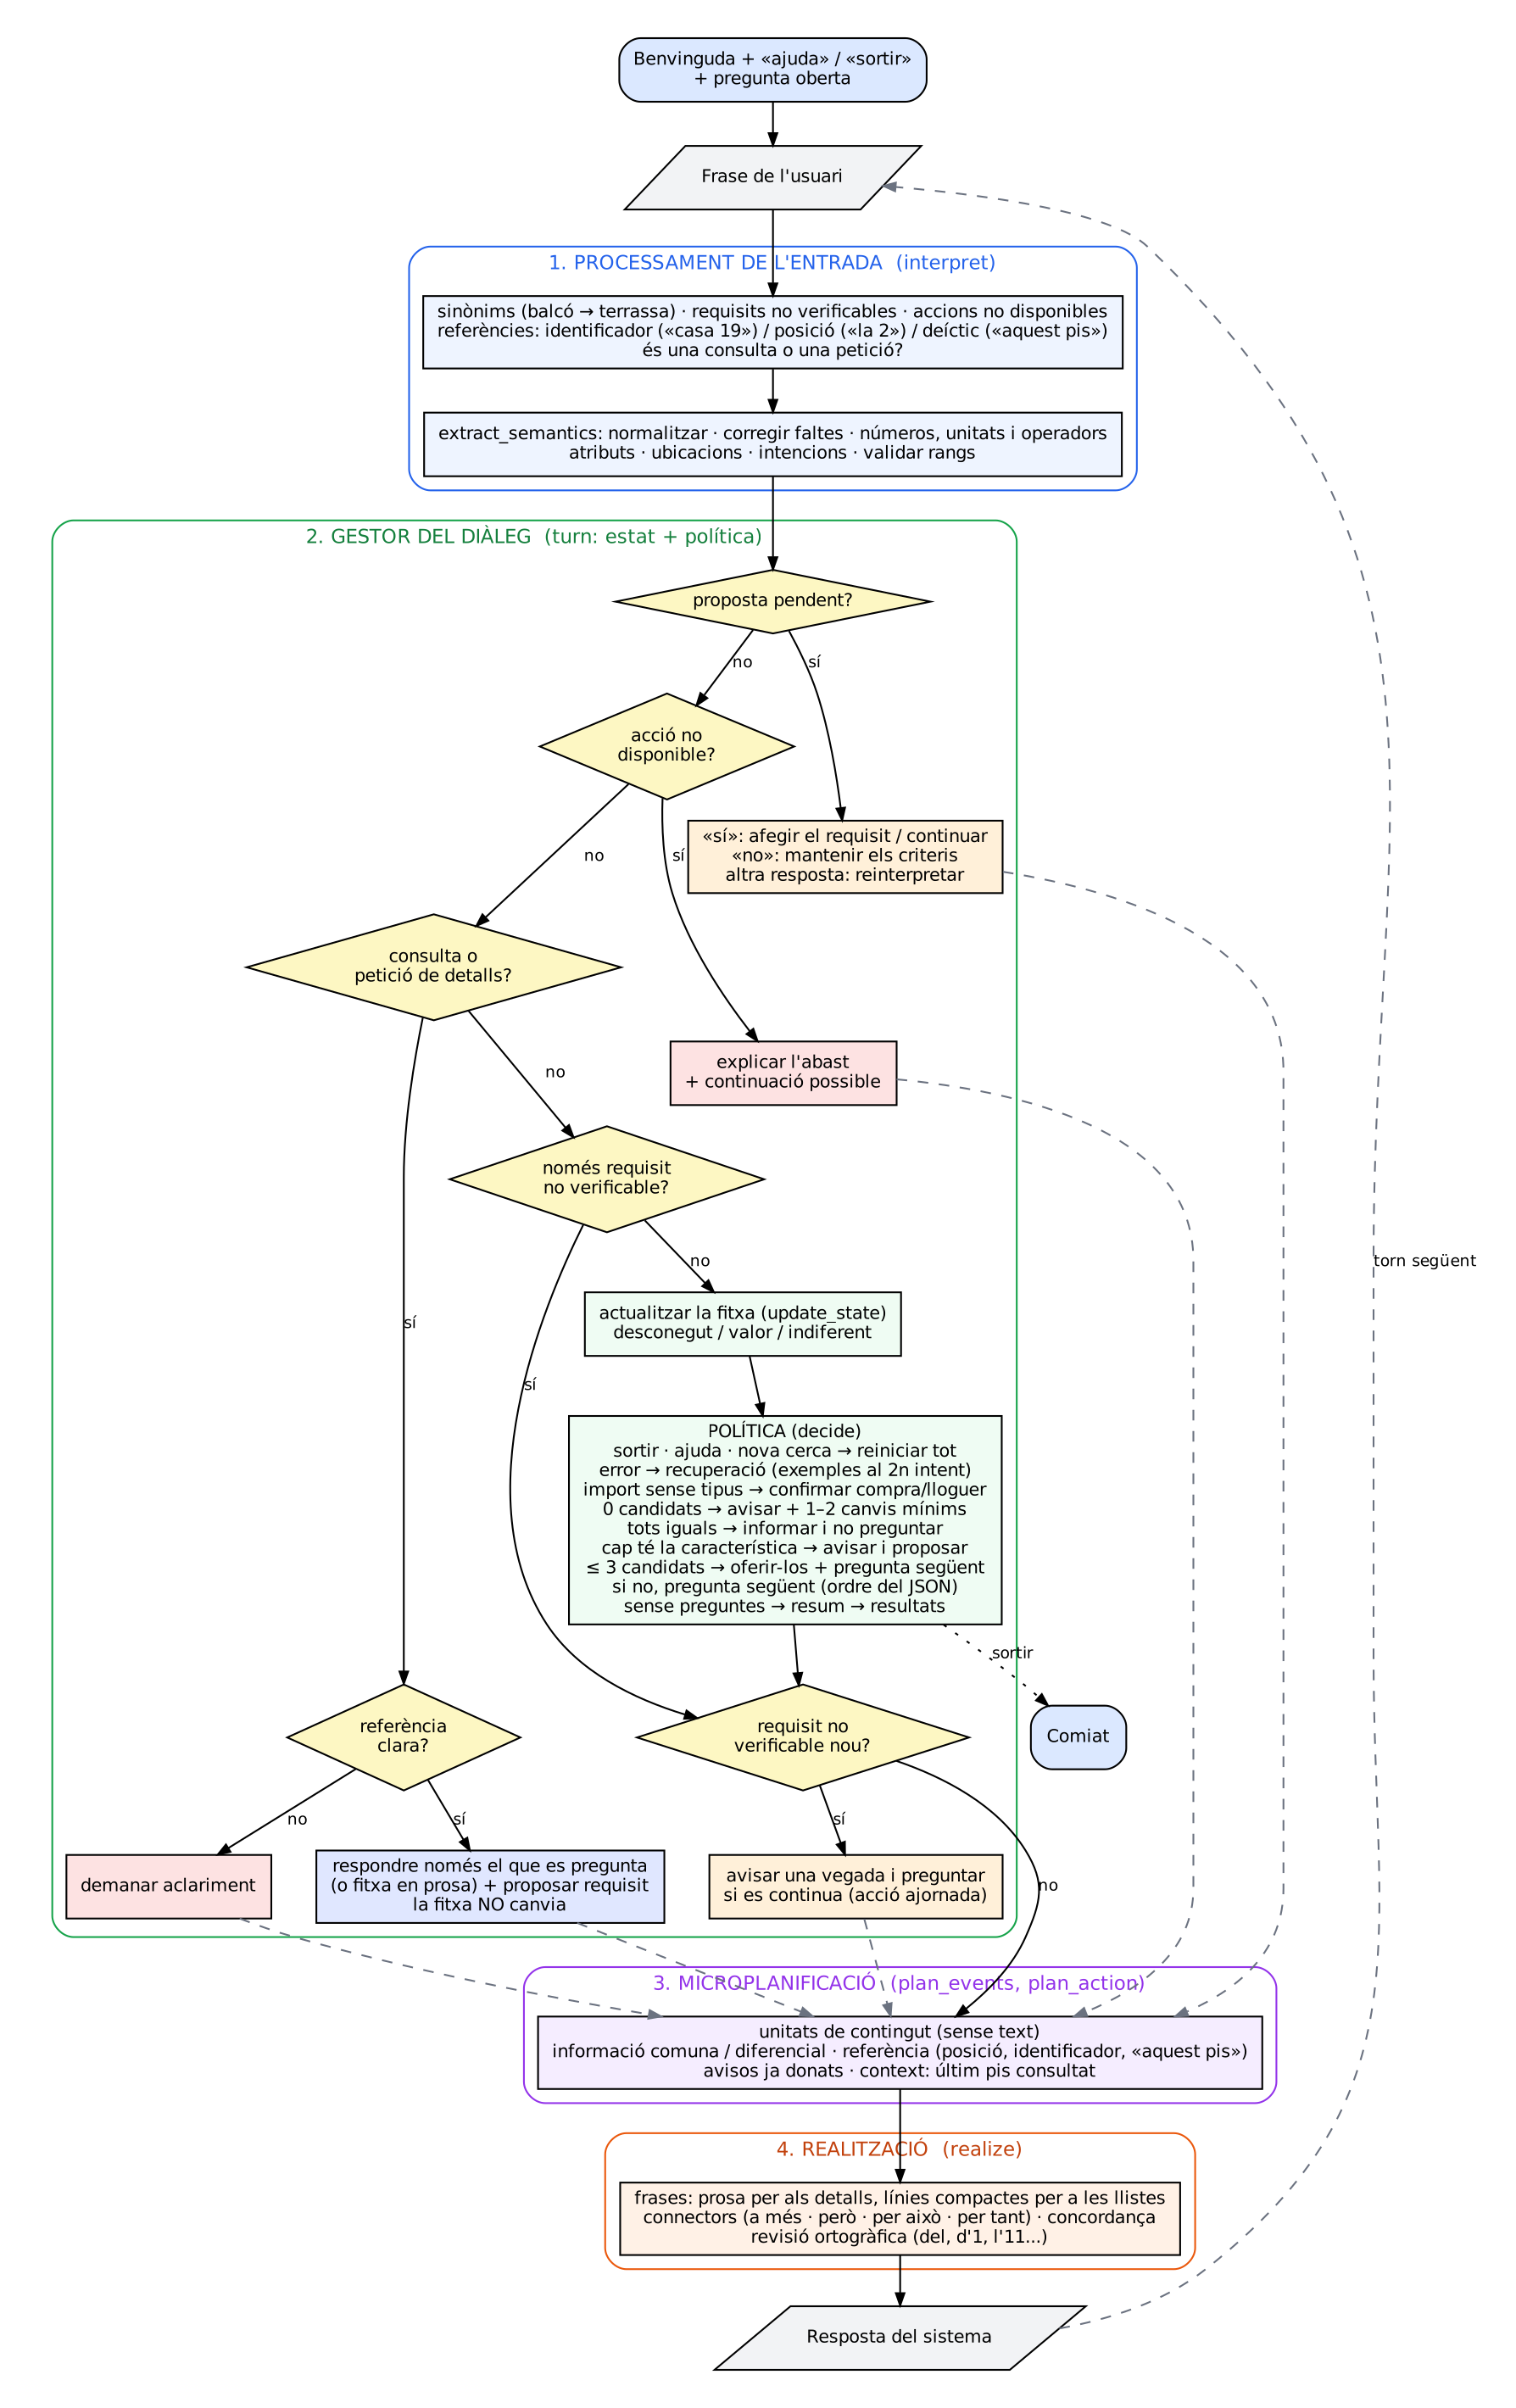

## 1. Configuració i càrrega del JSON

Del JSON es llegeixen:
* els pisos;
* les preguntes, amb el seu ordre de prioritat i les condicions (el pressupost només es pregunta per a compra; els ingressos, per a lloguer);
* els missatges fixos;
* els rangs vàlids de cada atribut.

Els preus del JSON són text (`"250k"`, `"1200"`) i es converteixen a números en una còpia de cada pis.

In [1]:
# ==== 1. CONFIGURACIÓ I DADES ===========================================================
import json
import re
import random
import unicodedata
import difflib

# Si s'executa a Colab, es munta Drive; si no, el JSON es llegeix del directori actual.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/TVD/house_data7.json'
except ImportError:
    DATA_PATH = 'house_data7.json'

with open(DATA_PATH, encoding='utf-8') as f:
    data = json.load(f)

REQUIRED_KEYS = ('houses', 'questions_ex7', 'messages_ex7', 'valid_ranges_ex7')
missing = [k for k in REQUIRED_KEYS if k not in data]
assert not missing, f"Al JSON hi falten les claus {missing}: cal la versió ampliada de house_data.json."

# ---- Configuració que ve del JSON ------------------------------------------------------
MESSAGES = data['messages_ex7']                     # benvinguda, pregunta oberta, ajuda, comiat
QUESTIONS = data['questions_ex7']                   # preguntes en ordre de prioritat (amb condicions)
RANGES = data['valid_ranges_ex7']                   # rang vàlid de cada atribut numèric
QUESTION_BY_SLOT = {q['answer_key']: q for q in QUESTIONS}
ASK_ORDER = [q['answer_key'] for q in QUESTIONS]

# ---- Constants de disseny --------------------------------------------------------------
ANY = 'ANY'            # valor «indiferent» (≠ atribut desconegut, que simplement no és a la fitxa)
RENT_SHARE = 0.35      # el lloguer no hauria de superar el 35 % dels ingressos mensuals
FEW_RESULTS = 3        # amb tan pocs candidats s'ofereix ensenyar-los abans d'acabar les preguntes
PAGE_SIZE = 3          # resultats per pàgina
MAX_FAILS = 2          # intents fallits abans d'afegir exemples de resposta

COUNT_SLOTS = ['bedrooms', 'bathrooms', 'square_meters', 'floor']   # filtren amb un mínim
MONEY_SLOTS = ['price', 'rent_max', 'income']                        # pressupost, lloguer màxim, ingressos
BOOL_SLOTS = ['terrace', 'elevator', 'commercial_use']               # només filtren amb «Yes»
INTEGER_SLOTS = {'bedrooms', 'bathrooms', 'floor'}
DEFAULT_OP = {'bedrooms': '>=', 'bathrooms': '>=', 'square_meters': '>=', 'floor': '>=',
              'price': '<=', 'rent_max': '<='}


def to_euros(value):
    """'250k' -> 250000.0 ; '1200' -> 1200.0 (format dels preus del JSON)."""
    s = str(value).strip().lower().replace('€', '')
    return float(s[:-1]) * 1000 if s.endswith('k') else float(s)


def house_record(h):
    """Còpia de la casa amb els camps convertits a números (el JSON no es modifica)."""
    return {'id': h['id'], 'type': h['type'], 'location': h['location'],
            'bedrooms': int(h['bedrooms']), 'bathrooms': int(h['bathrooms']),
            'square_meters': float(h['square_meters']), 'floor': int(h['floor']),
            'price': to_euros(h['price']),
            'terrace': h['terrace'], 'elevator': h['elevator'], 'commercial_use': h['commercial_use']}


HOUSES = [house_record(h) for h in data['houses']]
LOCATIONS = sorted({h['location'] for h in HOUSES})
print(f"{len(HOUSES)} pisos carregats de {DATA_PATH} · zones: {', '.join(LOCATIONS)}")
print('Ordre de les preguntes:', ' → '.join(ASK_ORDER))

26 pisos carregats de house_data7.json · zones: Barcelona, Esplugues de Llobregat, L'Hospitalet de Llobregat, Santa Coloma de Gramenet
Ordre de les preguntes: type → location → price → income → bedrooms → bathrooms → square_meters → floor → terrace → elevator → commercial_use


## 2. Lèxic

Tot el vocabulari està normalitzat (minúscules, sense accents, apòstrofs convertits en espai) i cobreix català, castellà i anglès. Inclou:
* intencions (sí, no, indiferent, sortir, ajuda, ensenyar, més, nova cerca...);
* paraules clau de cada atribut, ubicacions i barris, negacions;
* números, operadors i marques de període (anual o mensual);
* el lèxic per a les consultes: interrogatius, referències, deíctics, requisits no verificables (piscina, aparcament, jardí...) i accions que l'assistent no pot fer (visites, reserves, contacte...).

**Balcó és sinònim de terrassa.**

In [2]:
# ==== 2. LÈXIC ==========================================================================
# Tot el lèxic està normalitzat: minúscules, sense accents i amb els apòstrofs convertits en espais
# («m'és igual» -> «m es igual»). Cobreix català, castellà i anglès.

# ---- 2.1 Intencions, tipus d'operació, atributs i ubicacions ------------------------
INTENT_PHRASES = {
    'quit':        ['quit', 'exit', 'sortir', 'surt', 'adeu', 'adios', 'bye', 'goodbye', 'salir', 'fins aviat'],
    'help':        ['ajuda', 'help', 'ayuda', '?', 'que puc dir', 'que puedo decir'],
    'affirm':      ['si', 'yes', 'vale', 'val', 'd acord', 'dacord', 'ok', 'okay', 'clar', 'perfecte', 'correcte',
                    'exacte', 'sure', 'yep', 'yeah', 'de acuerdo', 'perfecto', 'correcto', 'claro', 'i tant',
                    'es clar', 'efectivament', 'endavant', 'adelante', 'genial'],
    'negate':      ['no', 'nop', 'nope', 'nah', 'tampoc', 'tampoco'],
    'indifferent': ['m es igual', 'me es igual', 'me da igual', 'igual', 'indiferent', 'indiferente',
                    'no m importa', 'no me importa', 'no importa', 'tant me fa', 'tan se val', 'tant se val',
                    'qualsevol', 'qualsevol cosa', 'cualquiera', 'cualquier', 'whatever', 'dont mind',
                    'don t mind', 'do not mind', 'dont care', 'don t care', 'no preference', 'sense preferencia',
                    'sin preferencia', 'com vulguis', 'lo que sea', 'el que sigui', 'no cal', 'any',
                    'no ho se', 'no se', 'ni idea', 'dont know', 'don t know', 'no lo se'],
    'show':        ['ensenya', 'ensenyam', 'ensenya m', 'ensenyem', 'mostra', 'mostram', 'mostra m', 'veure',
                    'vull veure', 'muestra', 'muestrame', 'muestramelos', 'show', 'resultats', 'resultados',
                    'results', 'ensenya mels', 'ensenya me ls', 'mostra mels'],
    'more':        ['mes', 'mas', 'more', 'seguents', 'siguientes', 'next', 'altres', 'otros', 'mes pisos',
                    'mes resultats', 'mas pisos'],
    'restart':     ['nova cerca', 'nova busqueda', 'comencar de nou', 'tornar a comencar', 'reinicia',
                    'reiniciar', 'nueva busqueda', 'empezar de nuevo', 'restart', 'start again', 'new search'],
    'continue':    ['continua', 'continuem', 'seguim', 'segueix', 'sigue', 'seguimos', 'continuar', 'continue',
                    'afinar', 'afinem', 'go on'],
    'done':        ['res mes', 'ja esta', 'nomes aixo', 'la resta igual', 'la resta m es igual', 'nada mas',
                    'eso es todo', 'el resto igual', 'el resto me da igual', 'nothing else', 'thats all',
                    'that s all'],
}
# Paraules massa curtes o ambigües: només compten com a intenció si són tota la resposta
WHOLE_ONLY = {'mes', 'mas', 'more', 'next', 'altres', 'otros', 'ok', 'val', 'clar', 'veure', 'continua', 'any'}

TYPE_WORDS = {
    'sale': ['compra', 'comprar', 'compro', 'comprant', 'compraria', 'buy', 'buying', 'purchase', 'sale',
             'venta', 'venda', 'adquirir', 'propietat', 'propiedad'],
    'rent': ['lloguer', 'llogar', 'llogo', 'llogaria', 'lloga', 'alquiler', 'alquilar', 'alquilo', 'rent',
             'renting', 'rental', 'arrendar', 'arrendament'],
}

# Paraules clau que indiquen a quin atribut es refereix un número
SLOT_KEYWORDS = {
    'bedrooms':      ['habitacio', 'habitacions', 'hab', 'habs', 'dormitori', 'dormitoris', 'habitacion',
                      'habitaciones', 'dormitorio', 'dormitorios', 'bedroom', 'bedrooms', 'room', 'rooms',
                      'cuarto', 'cuartos', 'h'],
    'bathrooms':     ['bany', 'banys', 'bano', 'banos', 'lavabo', 'lavabos', 'bathroom', 'bathrooms', 'bath',
                      'baths', 'wc', 'aseo', 'aseos', 'lavabos'],
    'square_meters': ['m', 'm2', 'metres', 'metre', 'metros', 'metro', 'meters', 'meter', 'mts', 'quadrats',
                      'cuadrados', 'square', 'superficie', 'sqm'],
    'floor':         ['planta', 'plantes', 'plantas', 'floor', 'altura'],
    'income':        ['ingressos', 'ingresos', 'income', 'guanyo', 'guanyem', 'gano', 'ganamos', 'cobro',
                      'cobrem', 'cobramos', 'sou', 'sueldo', 'salari', 'salario', 'nomina', 'nomines', 'earn',
                      'earnings', 'salary', 'renda', 'ingres'],
    'money':         ['euros', 'euro', 'eur', '€', 'pressupost', 'preu', 'presupuesto', 'precio', 'budget',
                      'price', 'pagar', 'gastar', 'costi', 'lloguer', 'alquiler', 'rent'],
}
KEYWORD_TO_SLOT = {w: s for s, ws in SLOT_KEYWORDS.items() for w in ws}

# Paraules per saber de quin atribut es parla quan no hi ha número ("m'és igual la zona")
SLOT_MENTIONS = {
    'type':          ['tipus', 'operacio', 'operacion'],
    'location':      ['zona', 'zones', 'ubicacio', 'lloc', 'ciutat', 'municipi', 'barri', 'poblacio',
                      'ubicacion', 'lugar', 'ciudad', 'location', 'area', 'city', 'place', 'where', 'on'],
    'price':         ['preu', 'pressupost', 'precio', 'presupuesto', 'budget', 'price'],
    'income':        SLOT_KEYWORDS['income'],
    'bedrooms':      SLOT_KEYWORDS['bedrooms'],
    'bathrooms':     SLOT_KEYWORDS['bathrooms'],
    'square_meters': ['metres', 'metros', 'meters', 'superficie', 'tamany', 'mida', 'tamano', 'size', 'm2'],
    'floor':         SLOT_KEYWORDS['floor'],
}

FEATURE_WORDS = {
    'terrace':        ['terrassa', 'terrasses', 'terraza', 'terrazas', 'terrace', 'terraces'],
    'elevator':       ['ascensor', 'ascensors', 'ascensores', 'elevator', 'elevators', 'lift'],
    'commercial_use': ['comercial', 'comercials', 'commercial', 'negoci', 'negocis', 'negocio', 'business',
                       'oficina', 'despatx', 'botiga', 'tienda', 'shop'],
}
NEGATORS = {'no', 'sense', 'sin', 'without', 'ni', 'tampoc', 'tampoco', 'cap'}
POSITIVES = {'amb', 'con', 'with'}

LOCATION_ALIASES = {
    'Barcelona':                 ['barcelona', 'bcn', 'barna'],
    "L'Hospitalet de Llobregat": ['l hospitalet de llobregat', 'hospitalet de llobregat', 'l hospitalet',
                                  'hospitalet', 'la hospitalet'],
    'Esplugues de Llobregat':    ['esplugues de llobregat', 'esplugues'],
    'Santa Coloma de Gramenet':  ['santa coloma de gramenet', 'santa coloma', 'coloma', 'gramenet'],
}
BCN_DISTRICTS = ['gracia', 'eixample', 'sants', 'les corts', 'sarria', 'sant gervasi', 'horta', 'guinardo',
                 'nou barris', 'sant andreu', 'sant marti', 'poblenou', 'ciutat vella', 'raval', 'gotic',
                 'born', 'barceloneta', 'montjuic', 'poble sec', 'sagrada familia', 'clot', 'vallcarca']
EXCLUDERS = {'menys', 'excepte', 'excepto', 'menos', 'except', 'excluding', 'sense', 'sin', 'no', 'tret',
             'fora', 'salvo'}
LOC_ADD = {'afegeix', 'afegir', 'afegim', 'tambe', 'tambien', 'also', 'add', 'anade', 'anadir'}
LOC_REMOVE = {'treu', 'treure', 'traieu', 'elimina', 'quita', 'quitar', 'remove', 'descarta'}
ALL_WORDS = {'qualsevol', 'tots', 'totes', 'tot', 'cualquier', 'cualquiera', 'todos', 'todas', 'any', 'all',
             'totes les zones', 'arreu'}


# ---- 2.2 Números, operadors i períodes -------------------------------------------------
# Números
NUM_WORDS = {'zero': 0, 'cero': 0, 'un': 1, 'una': 1, 'uno': 1, 'one': 1, 'dos': 2, 'dues': 2, 'two': 2,
             'tres': 3, 'three': 3, 'quatre': 4, 'cuatro': 4, 'four': 4, 'cinc': 5, 'cinco': 5, 'five': 5,
             'sis': 6, 'seis': 6, 'six': 6, 'set': 7, 'siete': 7, 'seven': 7, 'vuit': 8, 'ocho': 8,
             'eight': 8, 'nou': 9, 'nueve': 9, 'nine': 9, 'deu': 10, 'diez': 10, 'ten': 10}
AMBIGUOUS_NUM_WORDS = {'un', 'una', 'uno', 'one', 'set', 'nou', 'deu'}   # article / "nou" (nuevo) / "set" (set)
TENS_WORDS = {'vint': 20, 'trenta': 30, 'quaranta': 40, 'cinquanta': 50, 'seixanta': 60, 'setanta': 70,
              'vuitanta': 80, 'noranta': 90, 'veinte': 20, 'treinta': 30, 'cuarenta': 40, 'cincuenta': 50,
              'sesenta': 60, 'setenta': 70, 'ochenta': 80, 'noventa': 90, 'twenty': 20, 'thirty': 30,
              'forty': 40, 'fifty': 50, 'sixty': 60, 'seventy': 70, 'eighty': 80, 'ninety': 90,
              'onze': 11, 'dotze': 12, 'tretze': 13, 'catorze': 14, 'quinze': 15, 'once': 11, 'doce': 12,
              'quince': 15, 'eleven': 11, 'twelve': 12, 'fifteen': 15}
HUNDRED_WORDS = {'cent', 'cents', 'cien', 'ciento', 'cientos', 'hundred', 'hundreds'}
FIXED_HUNDREDS = {'doscientos': 200, 'trescientos': 300, 'cuatrocientos': 400, 'quinientos': 500,
                  'seiscientos': 600, 'setecientos': 700, 'ochocientos': 800, 'novecientos': 900,
                  'doscientas': 200, 'trescientas': 300, 'quinientas': 500}
NUMBER_LINKS = {'-', 'i', 'y', 'and'}
ORDINAL_WORDS = {'primer': 1, 'primera': 1, 'primero': 1, 'first': 1, 'segon': 2, 'segona': 2, 'segundo': 2,
                 'segunda': 2, 'second': 2, 'tercer': 3, 'tercera': 3, 'tercero': 3, 'third': 3, 'quart': 4,
                 'quarta': 4, 'cuarta': 4, 'fourth': 4, 'cinque': 5, 'cinquena': 5, 'quinto': 5, 'quinta': 5,
                 'fifth': 5, 'ultim': -1, 'ultima': -1, 'ultimo': -1, 'last': -1}
ORDINAL_SUFFIXES = {'a', 'r', 'o', 'er', 'n', 't', 'e', 'rd', 'th', 'st', 'nd', 'ra', 'na'}
GROUND_FLOOR = ['planta baixa', 'baixos', 'bajos', 'bajo', 'planta baja', 'ground floor', 'ground']
FLOOR_NOUNS = {'planta', 'pis', 'piso', 'floor'}
MULT_THOUSAND = {'k', 'mil', 'thousand'}
MULT_MILLION = {'milio', 'milions', 'millo', 'millon', 'millones', 'million', 'millions', 'mill', 'mm'}
CURRENCY = {'€', 'euros', 'euro', 'eur', 'e'}
SQM_UNITS = {'m', 'm2', 'metres', 'metre', 'metros', 'metro', 'meters', 'meter', 'mts', 'quadrats',
             'cuadrados', 'sqm'}
SEPARATORS = {',', ';', '.', '!'}
FILLERS = {'de', 'del', 'd', 'la', 'el', 'les', 'los', 'las', 'l', 'amb', 'con', 'with', 'of', 'a', 'en',
           'uns', 'unes', 'unos', 'unas', 'com', 'como', 'al', 'minim', 'maxim', 'minimo', 'maximo', 'menys',
           'mes', 'mas', 'menos', 'almenys', 'fins', 'hasta', 'up', 'to', 'at', 'least', 'most', 'than', 'more',
           'less', 'exactament', 'exactamente', 'exactly', 'per', 'para', 'por', ':', 'que', 'tenir', 'tener',
           'necessito', 'necesito', 'need', 'vull', 'quiero', 'want', 'minimum', 'maximum', 'some', 'about'}

OPERATORS_BEFORE = {
    '<=': ['com a maxim', 'maxim', 'com a max', 'max', 'menys de', 'fins a', 'fins', 'no mes de', 'como maximo',
           'maximo', 'menos de', 'hasta', 'at most', 'less than', 'up to', 'under', 'below', 'per sota de',
           'por debajo de', 'inferior a', 'no mas de', 'maximum'],
    '>':  ['mes de', 'mas de', 'more than', 'over', 'above', 'superior a', 'per sobre de', 'por encima de'],
    '>=': ['com a minim', 'minim', 'almenys', 'al menys', 'com a poc', 'como minimo', 'minimo', 'al menos',
           'at least', 'minimum', 'a partir de', 'des de', 'desde'],
    '==': ['exactament', 'exactamente', 'exactly', 'justament', 'nomes', 'solo', 'only', 'justo'],
}
OPERATORS_AFTER = {'>=': ['o mes', 'o mas', 'or more', 'com a minim', 'minim', 'como minimo', 'at least'],
                   '<=': ['o menys', 'o menos', 'or less', 'com a maxim', 'maxim', 'como maximo', 'at most']}
RANGE_START = {'entre', 'between', 'de', 'from', 'des', 'desde'}
RANGE_LINK = {'i', 'y', 'and', 'a', 'to', '-', 'o', 'or', 'fins', 'hasta'}

ANNUAL_MARKERS = ['a l any', 'al any', 'anuals', 'anual', 'anuales', 'per any', 'per year', 'a year', 'annual',
                  'annually', 'yearly', 'al ano', 'por ano', 'l any']
MONTHLY_MARKERS = ['al mes', 'mensuals', 'mensual', 'mensuales', 'per mes', 'a month', 'per month', 'monthly',
                   'cada mes', 'mes']

# Paraules que introdueixen l'identificador d'un pis («casa 19», «#19», «pis número 19»)
REF_ID_WORDS = {'casa', 'pis', 'piso', 'house', '#', 'id', 'ref', 'referencia', 'habitatge', 'vivienda',
                'num', 'numero'}

# Paraules del domini que NO s'han de "corregir" com si fossin faltes
PROTECTED = {'habitatge', 'habitatges', 'vivienda', 'viviendas', 'busco', 'buscar', 'necessito', 'necesito',
             'tenim', 'tinc', 'tengo', 'tenir', 'tener', 'quiero', 'voldria', 'pisos', 'casas', 'cases',
             'familia', 'fills', 'hijos', 'parella', 'pareja', 'gracies', 'gracias', 'thanks', 'llegar',
             'compartir', 'quiero', 'tambe', 'tambien', 'treballo', 'trabajo', 'preferencia', 'prefereixo',
             'prefiero', 'detall', 'detalls', 'detalles', 'details', 'informacio', 'informacion', 'please',
             'porfa', 'thanks', 'perque', 'porque', 'because', 'pero', 'aquest', 'aquesta', 'aquests', 'quants',
             'quantes', 'cuantos', 'cuantas', 'there', 'where', 'which', 'would', 'could', 'should', 'about'}


def _vocabulary():
    words = set()
    groups = [INTENT_PHRASES.values(), TYPE_WORDS.values(), SLOT_KEYWORDS.values(), SLOT_MENTIONS.values(),
              FEATURE_WORDS.values(), LOCATION_ALIASES.values(), OPERATORS_BEFORE.values(), OPERATORS_AFTER.values(),
              [BCN_DISTRICTS], [NUM_WORDS], [TENS_WORDS], [HUNDRED_WORDS], [FIXED_HUNDREDS], [ORDINAL_WORDS], [FILLERS], [RANGE_START], [RANGE_LINK], [EXCLUDERS],
              [LOC_ADD], [LOC_REMOVE], [NEGATORS], [POSITIVES], [ALL_WORDS], [REF_ID_WORDS], [MULT_THOUSAND],
              [MULT_MILLION], [SQM_UNITS], [ANNUAL_MARKERS], [MONTHLY_MARKERS], [GROUND_FLOOR]]
    for group in groups:
        for phrases in group:
            for p in phrases:
                words.update(p.split())
    return words


VOCAB = _vocabulary()
VOCAB_LONG = sorted(w for w in VOCAB if len(w) >= 5)

# ---- 2.3 Consultes, referències, requisits no verificables i accions --------------------
# Sinònims que s'apliquen abans de l'extracció (balcó = terrassa)
SYNONYMS = {'balco': 'terrassa', 'balcons': 'terrassa', 'balcon': 'terrassa', 'balcones': 'terrassa',
            'balcony': 'terrassa', 'balconies': 'terrassa'}            # balcó = terrassa

# Requisits que l'usuari pot demanar però que NO són a les dades: no es poden verificar.
#   topic: «no disposo d'informació sobre ...»   name: per a recordatoris («no puc comprovar ...»)
#   sg / subj: per dir «no puc saber si la casa 19 té piscina» / «no garanteixen que tinguin piscina»
UNVERIFIABLE = {
    'piscina':    {'words': ['piscina', 'piscines', 'piscinas', 'pool', 'swimming pool'],
                   'topic': 'piscines', 'name': 'la piscina', 'sg': 'té piscina', 'subj': 'tinguin piscina'},
    'aparcament': {'words': ['aparcament', 'aparcaments', 'parquing', 'parking', 'garatge', 'garatges', 'garaje',
                             'garajes', 'aparcamiento', 'garage', 'cotxera', 'placa d aparcament'],
                   'topic': "l'aparcament", 'name': "l'aparcament", 'sg': 'té aparcament', 'subj': 'tinguin aparcament'},
    'jardi':      {'words': ['jardi', 'jardins', 'jardin', 'jardines', 'garden', 'gardens', 'pati', 'patio'],
                   'topic': 'jardins', 'name': 'el jardí', 'sg': 'té jardí', 'subj': 'tinguin jardí'},
    'traster':    {'words': ['traster', 'trasters', 'trastero', 'trasteros', 'storage room'],
                   'topic': 'trasters', 'name': 'el traster', 'sg': 'té traster', 'subj': 'tinguin traster'},
    'calefaccio': {'words': ['calefaccio', 'calefaccion', 'heating'],
                   'topic': 'la calefacció', 'name': 'la calefacció', 'sg': 'té calefacció', 'subj': 'tinguin calefacció'},
    'aire':       {'words': ['aire condicionat', 'aire acondicionado', 'air conditioning', 'climatitzacio',
                             'climatizacion'],
                   'topic': "l'aire condicionat", 'name': "l'aire condicionat", 'sg': 'té aire condicionat',
                   'subj': 'tinguin aire condicionat'},
    'moblat':     {'words': ['moblat', 'moblada', 'moblats', 'moblades', 'mobles', 'amueblado', 'amueblada',
                             'furnished'],
                   'topic': 'el mobiliari', 'name': 'el mobiliari', 'sg': 'està moblat', 'subj': 'estiguin moblats'},
    'mascotes':   {'words': ['mascota', 'mascotes', 'mascotas', 'gos', 'gossos', 'gat', 'gats', 'perro', 'perros',
                             'gato', 'gatos', 'pet', 'pets'],
                   'topic': "l'admissió de mascotes", 'name': "l'admissió de mascotes", 'sg': 'admet mascotes',
                   'subj': 'admetin mascotes'},
    'vistes':     {'words': ['vistes', 'vistas', 'views', 'vista al mar', 'vistes al mar'],
                   'topic': 'les vistes', 'name': 'les vistes', 'sg': 'té vistes', 'subj': 'tinguin vistes'},
    'transport':  {'words': ['metro', 'transport public', 'transporte publico', 'public transport', 'autobus', 'bus',
                             'estacio', 'estacion', 'tren', 'renfe', 'fgc', 'tramvia'],
                   'topic': 'la proximitat al transport públic', 'name': 'la proximitat al transport públic',
                   'sg': 'és a prop del transport públic', 'subj': 'siguin a prop del transport públic'},
}

# Accions que l'assistent no pot fer (recuperació «acció no disponible»)
UNAVAILABLE_ACTIONS = {
    'visit':     {'words': ['visita', 'visites', 'visitar', 'visitarlo', 'visit', 'cita', 'agendar'],
                  'text': 'programar visites'},
    'reserve':   {'words': ['reserva', 'reservar', 'reservarlo', 'book', 'senyal'], 'text': 'fer reserves'},
    'contact':   {'words': ['trucar', 'truca', 'trucada', 'telefon', 'telefono', 'llamar', 'llama', 'call',
                            'contactar', 'contacte', 'contact', 'propietari', 'propietario', 'owner'],
                  'text': "posar-te en contacte amb l'agència o amb el propietari"},
    'send':      {'words': ['correu', 'email', 'mail', 'envia', 'enviar', 'enviame', 'whatsapp', 'sms'],
                  'text': 'enviar informació per correu ni per missatge'},
    'finance':   {'words': ['hipoteca', 'hipoteques', 'financament', 'financiacion', 'prestec', 'prestamo',
                            'mortgage', 'loan'],
                  'text': 'donar informació sobre hipoteques ni finançament'},
    'negotiate': {'words': ['negociar', 'regatejar', 'descompte', 'descuento', 'oferta', 'ofertar'],
                  'text': 'negociar preus ni fer ofertes'},
    'contract':  {'words': ['contracte', 'contractes', 'signar', 'firmar', 'contrato', 'sign'],
                  'text': 'gestionar contractes'},
}

INTERROGATIVES = {'te', 'tenen', 'tiene', 'tienen', 'has', 'have', 'does', 'do', 'quant', 'quants', 'quanta',
                  'quantes', 'cuanto', 'cuanta', 'cuantos', 'cuantas', 'how', 'quin', 'quina', 'quins', 'quines',
                  'cual', 'cuales', 'which', 'what', 'on', 'donde', 'where', 'es', 'esta', 'is', 'are', 'costa',
                  'cuesta', 'admet', 'admeten', 'admite', 'accepta', 'fa', 'mide', 'hi'}
REQUEST_VERBS = {'busca', 'busco', 'buscar', 'busques', 'cercar', 'vull', 'voldria', 'necessito', 'agradaria',
                 'quiero', 'quisiera', 'necesito', 'want', 'need', 'find', 'search', 'afegeix', 'afegir', 'treu',
                 'canvia', 'canviar', 'posa', 'prefereixo', 'prefiero'}
ASK_EXCEPTIONS = {'saber', 'digues', 'dime', 'tell', 'dir'}           # «vull saber si...» sí que és consulta
OFFER_QUESTION_PHRASES = ['hi ha', 'hay', 'there are', 'there is', 'teniu', 'tens', 'tienes', 'teneis', 'do you have',
                          'queden', 'quedan']
SHOW_PHRASES = ['quins son', 'quines son', 'cuales son', 'which are', 'which ones']
FOLLOWUP_WORDS = {'i', 'y', 'and', 'tambe', 'tambien'}
DEICTICS = {'aquest', 'aquesta', 'aquell', 'aquella', 'este', 'esta', 'this', 'that', 'ese', 'esa'}
POSITION_NOUNS = {'resultat', 'resultats', 'opcio', 'opcion', 'result', 'option'}
DETAIL_WORDS = {'detall', 'detalls', 'detalles', 'detalle', 'details', 'detail', 'fitxa', 'ficha', 'info',
                'informacio', 'informacion', 'dades', 'datos', 'descripcio', 'descripcion', 'descriu'}
GREETINGS = {'hola', 'bon', 'bona', 'dia', 'tarda', 'nit', 'bones', 'buenas', 'buenos', 'dias', 'hello', 'hi',
             'hey', 'salut', 'ei', 'ep'}
THANKS = {'gracies', 'gracias', 'thanks', 'thank', 'you', 'merci', 'moltes'}

# Paraules que indiquen per quin atribut es pregunta quan no hi ha cap valor («quant costa?», «on és?»)
QUESTION_ATTR_WORDS = {
    'price':         {'preu', 'precio', 'price', 'costa', 'cuesta', 'cost', 'costen', 'cuestan', 'val', 'valen',
                      'car', 'cara', 'barat', 'barata', 'caro', 'barato'},
    'location':      {'on', 'donde', 'where', 'zona', 'ubicacio', 'ubicacion', 'situat', 'situada', 'ciutat',
                      'municipi', 'barri'},
    'type':          {'tipus', 'tipo', 'operacio'},
    'bedrooms':      set(SLOT_KEYWORDS['bedrooms']) - {'h'},
    'bathrooms':     set(SLOT_KEYWORDS['bathrooms']),
    'square_meters': {'metres', 'metros', 'meters', 'm2', 'superficie', 'mida', 'tamany', 'tamano', 'size',
                      'gran', 'grande', 'big'},
    'floor':         {'planta', 'altura', 'floor'},
}
# Interrogatius que el corrector de faltes confondria amb ordinals («quant» -> «quart»)
DROP_BEFORE_EXTRACTION = {'quant', 'quanta', 'quants', 'quantes', 'quin', 'quina', 'quins', 'quines'}
NO_REF_FOLLOWERS = set(KEYWORD_TO_SLOT) | SQM_UNITS | FLOOR_NOUNS | MULT_THOUSAND | MULT_MILLION | CURRENCY

## 3. Processament de l'entrada

`interpret(text, context)` converteix la frase en una representació semàntica. El `context` indica:
* quina pregunta està pendent;
* el tipus d'operació, si ja se sap;
* si hi ha una llista de resultats a la vista.

**Pas 1. Abans de l'extracció**
* Aplica els sinònims.
* Marca i treu els requisits no verificables i les accions no disponibles.
* Distingeix l'identificador d'un pis («casa 19») de la seva posició a la llista («la 2», «la segona»).
* Detecta els deíctics («aquest pis»).
* Decideix si la frase és una **consulta** o una **petició**. És una consulta si és interrogativa i no té cap verb de petició («busco», «vull»...).

**Pas 2. Extracció d'atributs** (`extract_semantics`)
* Normalització i correcció de faltes: `difflib` amb un llindar de 0,8, només per a paraules de 5 lletres o més.
* Números en lletres, separadors, multiplicadors (`k`, `mil`, `milió`) i unitats.
* Assignació de cada número a l'atribut de la paraula clau que té al costat.
* Operadors i intervals, tipus d'operació, ubicacions (incloses i excloses), característiques amb negació i intencions.
* Validació de rangs.

In [3]:
# ==== 3. PROCESSAMENT DE L'ENTRADA ========================================================
# Pas 1: normalització, tokenització i correcció de faltes.
def strip_accents(text):
    return ''.join(c for c in unicodedata.normalize('NFKD', text) if not unicodedata.combining(c))


def normalize(text):
    """Minúscules, sense accents, apòstrofs unificats i convertits en espai, m² -> m2."""
    t = text.lower().replace('m²', 'm2').replace('²', '2').replace('€', ' € ')
    t = re.sub(r"[’‘´`]", "'", t)
    t = strip_accents(t).replace('l·l', 'll').replace('l.l', 'll')
    return t.replace("'", ' ')


TOKEN_RE = re.compile(r"\d+(?:[.,]\d+)*(?:[a-z]+2?)?|\bm2(?!\d)|[a-z]+|[€?#,;.!:\-]")


def tokenize(norm_text):
    return TOKEN_RE.findall(norm_text)


def correct_typos(tokens):
    """Corregeix faltes comparant cada paraula llarga desconeguda amb el lèxic (difflib, llindar 0,8)."""
    fixed, corrections = [], []
    for t in tokens:
        if t.isalpha() and len(t) >= 5 and t not in VOCAB and t not in PROTECTED:
            match = difflib.get_close_matches(t, VOCAB_LONG, n=1, cutoff=0.8)
            if match:
                fixed.append(match[0])
                corrections.append((t, match[0]))
                continue
        fixed.append(t)
    return fixed, corrections


def find_phrase(tokens, phrase):
    """Posicions on apareix una expressió (llista de paraules) dins dels tokens."""
    p = phrase.split()
    n = len(p)
    return [i for i in range(len(tokens) - n + 1) if tokens[i:i + n] == p]


def has_phrase(tokens, phrases):
    return any(find_phrase(tokens, p) for p in phrases)

def parse_digits(s):
    """'1.500' -> 1500 ; '1,500' -> 1500 ; '2,5' -> 2.5 ; '250.000' -> 250000 ; '1.500,50' -> 1500.5"""
    if '.' in s and ',' in s:                                  # el darrer separador és el decimal
        dec = '.' if s.rfind('.') > s.rfind(',') else ','
        thou = ',' if dec == '.' else '.'
        return float(s.replace(thou, '').replace(dec, '.'))
    for sep in '.,':
        if sep in s:
            parts = s.split(sep)
            if all(len(p) == 3 for p in parts[1:]):            # grups de 3 xifres -> separador de milers
                return float(''.join(parts))
            if len(parts) == 2:
                return float(parts[0] + '.' + parts[1])        # decimal
            return float(''.join(parts))
    return float(s)


def merge_number_words(toks):
    """Converteix seqüències de números en lletres en xifres: 'dos-cents mil' -> '200000', 'vint-i-dos' -> '22'."""
    words = set(NUM_WORDS) | set(TENS_WORDS) | HUNDRED_WORDS | set(FIXED_HUNDREDS) | {'mil', 'thousand'}
    out, i = [], 0
    while i < len(toks):
        if toks[i] not in words or toks[i] in ('mil', 'thousand'):
            out.append(toks[i]); i += 1
            continue
        j, seq = i, []
        while j < len(toks):
            if toks[j] in words:
                seq.append(toks[j]); j += 1
                continue
            k = j                                            # enllaços: "-", "-i-", " y "
            while k < len(toks) and toks[k] in NUMBER_LINKS:
                k += 1
            links = toks[j:k]
            if seq and k < len(toks) and toks[k] in words and links and \
                    ('-' in links or seq[-1] in TENS_WORDS) and len(links) <= 3:
                j = k
            else:
                break
        nxt = toks[j] if j < len(toks) else ''
        nxt2 = toks[j + 1] if j + 1 < len(toks) else ''
        if len(seq) == 1 and seq[0] in AMBIGUOUS_NUM_WORDS and len(toks) > 1 \
                and nxt not in KEYWORD_TO_SLOT and nxt2 not in KEYWORD_TO_SLOT and nxt not in MULT_MILLION:
            out.append(toks[i]); i += 1                    # "un pis", "pis nou": no és un número
            continue
        total, current = 0, 0
        for w in seq:
            if w in NUM_WORDS:
                current += NUM_WORDS[w]
            elif w in TENS_WORDS:
                current += TENS_WORDS[w]
            elif w in FIXED_HUNDREDS:
                current += FIXED_HUNDREDS[w]
            elif w in HUNDRED_WORDS:
                current = max(current, 1) * 100
            elif w in ('mil', 'thousand'):
                total += max(current, 1) * 1000
                current = 0
        out.append(str(total + current))
        i = j
    return out


def extract_numbers(toks):
    """Troba els números (xifres o paraules) amb les seves unitats i multiplicadors."""
    nums, i = [], 0
    while i < len(toks):
        t = toks[i]
        m = re.fullmatch(r"(\d+(?:[.,]\d+)*)([a-z]+2?)?", t)
        value, suffix = None, ''
        if m:
            value, suffix = parse_digits(m.group(1)), (m.group(2) or '')
        elif t == 'mil' and not (nums and nums[-1]['end'] == i - 1):
            value = 1000.0                                  # "mil euros"
        if value is None:
            i += 1
            continue

        n = {'value': value, 'start': i, 'end': i, 'money': False, 'mult': False, 'unit': None,
             'ordinal': False, 'negative': i > 0 and toks[i - 1] == '-'}
        # sufix enganxat al número: 250k, 80m2, 3a, 2h, 900e...
        if suffix in MULT_THOUSAND:
            n['value'] *= 1000; n['money'] = n['mult'] = True
        elif suffix in ('m', 'mm') and value < 5:
            n['value'] *= 1_000_000; n['money'] = n['mult'] = True
        elif suffix in SQM_UNITS:
            n['unit'] = 'square_meters'
        elif suffix in ORDINAL_SUFFIXES:
            n['ordinal'] = True
        elif suffix in ('h', 'hab', 'habs'):
            n['unit'] = 'bedrooms'
        elif suffix in CURRENCY:
            n['money'] = True
        # paraules següents: "250 mil euros", "1 milió", "80 m2"
        j = i + 1
        while j < len(toks):
            nt = toks[j]
            if nt in MULT_THOUSAND and not n['mult']:
                n['value'] *= 1000; n['money'] = n['mult'] = True
            elif nt in MULT_MILLION or (nt == 'm' and n['value'] < 5):
                n['value'] *= 1_000_000; n['money'] = n['mult'] = True
            elif nt in CURRENCY:
                n['money'] = True
            elif nt in SQM_UNITS and n['unit'] is None:
                n['unit'] = 'square_meters'
            else:
                break
            j += 1
        n['end'] = j - 1
        nums.append(n)
        i = j
    # ordinals escrits amb lletres ("tercera planta")
    for k, t in enumerate(toks):
        if t in ORDINAL_WORDS and ORDINAL_WORDS[t] > 0 and k + 1 < len(toks) and toks[k + 1] in FLOOR_NOUNS:
            nums.append({'value': float(ORDINAL_WORDS[t]), 'start': k, 'end': k, 'money': False, 'mult': False,
                         'unit': 'floor', 'ordinal': True, 'negative': False})
    nums.sort(key=lambda n: n['start'])
    return nums


def keyword_for(toks, n, is_num):
    """A quin atribut es refereix un número, mirant les paraules del voltant:
    1) paraula clau just després  2) just abans  3) finestra endavant  4) finestra enrere."""
    s, e = n['start'], n['end']
    j = e + 1                                                       # 1) just després ("3 habitacions")
    if j < len(toks) and toks[j] in FILLERS and j + 1 < len(toks) and not is_num(j + 1):
        j += 1
    if j < len(toks) and toks[j] in KEYWORD_TO_SLOT:
        return KEYWORD_TO_SLOT[toks[j]]
    j, skipped = s - 1, 0                                           # 2) just abans ("habitacions: 3")
    while j >= 0 and toks[j] in FILLERS and skipped < 3:
        j -= 1; skipped += 1
    if j >= 0 and toks[j] in KEYWORD_TO_SLOT:
        return KEYWORD_TO_SLOT[toks[j]]
    for j in range(e + 1, min(len(toks), e + 4)):                   # 3) endavant
        if is_num(j) or toks[j] in SEPARATORS:
            break
        if toks[j] in KEYWORD_TO_SLOT:
            return KEYWORD_TO_SLOT[toks[j]]
    for j in range(s - 1, max(-1, s - 5), -1):                      # 4) enrere
        if is_num(j) or toks[j] in SEPARATORS:
            break
        if toks[j] in KEYWORD_TO_SLOT:
            return KEYWORD_TO_SLOT[toks[j]]
    return None


def operator_for(toks, n, prev_end):
    """Operador de comparació: 'com a màxim 3' -> <= ; 'més de 2' -> > ; '3 o més' -> >= ..."""
    before = toks[max(prev_end + 1, n['start'] - 4):n['start']]
    after = toks[n['end'] + 1:n['end'] + 4]
    for op in ('<=', '>', '>=', '=='):                  # '<=' primer: "no més de" conté "més de"
        if has_phrase(before, OPERATORS_BEFORE[op]):
            return op
    for op, phrases in OPERATORS_AFTER.items():
        if any(find_phrase(after, p) and find_phrase(after, p)[0] == 0 for p in phrases):
            return op
    return None

def extract_type(toks):
    found = set()
    for typ, words in TYPE_WORDS.items():
        for k, t in enumerate(toks):
            if t in words and not (k > 0 and toks[k - 1] in NEGATORS):
                found.add(typ)
    return found


def extract_locations(toks):
    """Retorna (incloses, excloses, mode, barris) a partir de totes les ubicacions de la frase."""
    include, exclude, districts, used = set(), set(), [], set()
    candidates = [(alias, loc) for loc, aliases in LOCATION_ALIASES.items() for alias in aliases]
    candidates += [(d, 'Barcelona#' + d) for d in BCN_DISTRICTS]
    for alias, loc in sorted(candidates, key=lambda x: -len(x[0].split())):   # el més llarg primer
        for start in find_phrase(toks, alias):
            span = set(range(start, start + len(alias.split())))
            if span & used:
                continue
            used |= span
            excluded = any(toks[k] in EXCLUDERS for k in range(max(0, start - 3), start))
            if loc.startswith('Barcelona#'):
                districts.append(alias)
                loc = 'Barcelona'
            (exclude if excluded else include).add(loc)
    mode = 'replace'
    if include or exclude:
        if any(t in LOC_ADD for t in toks):
            mode = 'add'
        elif any(t in LOC_REMOVE for t in toks):
            mode, exclude, include = 'remove', include | exclude, set()
    return include, exclude, mode, districts


def extract_features(toks, indifferent):
    feats = {}
    for slot, words in FEATURE_WORDS.items():
        for k, t in enumerate(toks):
            if t not in words:
                continue
            if indifferent:
                feats[slot] = ANY
                continue
            value = 'Yes'
            for j in range(k - 1, max(-1, k - 4), -1):      # mirem fins a 3 paraules enrere
                if toks[j] in POSITIVES or toks[j] in SEPARATORS:
                    break
                if toks[j] in NEGATORS:
                    value = 'No'
                    break
            feats[slot] = value
    return feats


def detect_intents(toks):
    intents = set()
    whole = ' '.join(t for t in toks if t not in SEPARATORS)
    for intent, phrases in INTENT_PHRASES.items():
        for p in phrases:
            if p in WHOLE_ONLY:
                if whole == p:
                    intents.add(intent)
            elif find_phrase(toks, p):
                intents.add(intent)
    if 'indifferent' in intents and any(p in whole for p in ('no m importa', 'no importa', 'no cal', 'no ho se',
                                                             'no se', 'no lo se', 'no me importa')):
        intents.discard('negate')
    return intents

def extract_semantics(text, context=None):
    """Extracció d'atributs: text -> representació semàntica (atributs, imports, intencions, errors...).
    context = {'expected': atribut que s'acaba de preguntar (o None), 'type': tipus d'operació ja conegut}"""
    context = context or {}
    expected, known_type = context.get('expected'), context.get('type')
    I = {'text': text, 'slots': {}, 'money': [], 'intents': set(), 'errors': [], 'notes': [],
         'unassigned': [], 'ref_id': None, 'ref_index': None, 'loc_mode': 'replace', 'empty': False,
         'corrections': []}
    norm = normalize(text)
    toks = tokenize(norm)
    if not toks:
        I['empty'] = True
        return I
    toks, I['corrections'] = correct_typos(toks)
    toks = merge_number_words(toks)

    # Marques de període (ingressos anuals/mensuals). Les traiem perquè "any" (=año) i "mes" (=month)
    # no es confonguin amb "any" (=indiferent) o "més" (=more).
    annual = has_phrase(toks, ANNUAL_MARKERS)
    monthly = has_phrase(toks, MONTHLY_MARKERS) and not has_phrase(toks, ['mes de', 'o mes', 'mes pisos'])
    clean = list(toks)
    for marker in ANNUAL_MARKERS + ['al mes', 'per mes', 'cada mes']:
        for pos in find_phrase(clean, marker):
            for k in range(pos, pos + len(marker.split())):
                clean[k] = '_'
    I['intents'] = detect_intents([t for t in clean if t != '_'])
    intents = I['intents']

    # --- tipus d'operació --------------------------------------------------------
    types = extract_type(toks)
    if len(types) == 1:
        I['slots']['type'] = types.pop()
    elif len(types) == 2:
        if 'indifferent' in intents:
            I['slots']['type'] = ANY
        else:
            I['errors'].append(('ambiguous_type', None))

    # --- ubicacions ----------------------------------------------------------------
    include, exclude, mode, districts = extract_locations(toks)
    if include or exclude:
        if exclude and (not include or any(t in ALL_WORDS for t in toks)):
            include = set(LOCATIONS) - exclude if not include else include - exclude
            mode = 'replace' if mode != 'remove' else 'remove'
        locs = (exclude or include) if mode == 'remove' else include - exclude
        if locs:
            I['slots']['location'] = locs
        else:                                              # "Barcelona... no, Barcelona no": contradictori
            I['errors'].append(('ambiguous_location', None))
        I['loc_mode'] = mode
        for d in districts:
            I['notes'].append(('district', d))

    # --- característiques (terrassa, ascensor, ús comercial) -------------------------
    mentioned = {s for s, ws in SLOT_MENTIONS.items() if any(t in ws for t in toks)}
    I['slots'].update(extract_features(toks, 'indifferent' in intents))

    # --- números -----------------------------------------------------------------
    nums = extract_numbers(toks)
    num_pos = {k for n in nums for k in range(n['start'], n['end'] + 1)}
    is_num = lambda k: k in num_pos
    # referències a resultats: "casa 19", "#19"
    for n in list(nums):
        if n['start'] > 0 and toks[n['start'] - 1] in REF_ID_WORDS and not n['money'] and n['unit'] is None \
                and keyword_for(toks, n, is_num) is None:
            I['ref_id'] = int(n['value'])
            nums.remove(n)
    # rangs: "entre 60 i 80", "de 2 a 3", "2 o 3"
    groups, k = [], 0
    while k < len(nums):
        a = nums[k]
        if k + 1 < len(nums):
            b = nums[k + 1]
            link = toks[a['end'] + 1:b['start']]
            starts = a['start'] > 0 and toks[a['start'] - 1] in RANGE_START
            if len(link) == 1 and link[0] in RANGE_LINK and (starts or link[0] in ('o', 'or')):
                if b['mult'] and not a['mult'] and a['value'] < 1000:
                    a = dict(a, value=a['value'] * 1000)
                groups.append([a, b]); k += 2
                continue
        groups.append([a]); k += 1

    prev_end, slot_filled = -1, set()
    for g in groups:
        first, last = g[0], g[-1]
        if any(n['negative'] for n in g):
            I['errors'].append(('negative', None)); prev_end = last['end']; continue
        # a quin atribut va?
        if first['ordinal'] and (first['unit'] == 'floor' or keyword_for(toks, last, is_num) == 'floor'
                                 or (last['end'] + 1 < len(toks) and toks[last['end'] + 1] in FLOOR_NOUNS)):
            slot = 'floor'
        elif last['unit'] or first['unit']:
            slot = last['unit'] or first['unit']
        else:
            slot = keyword_for(toks, last, is_num) or keyword_for(toks, first, is_num)
            if slot is None and (first['money'] or last['money']):
                # "3k" quan preguntem habitacions: és un número fora de rang, no un import
                slot = expected if expected in COUNT_SLOTS else 'money'
        op = operator_for(toks, first, prev_end)
        values = [n['value'] for n in g]
        prev_end = last['end']
        if slot is None:
            I['unassigned'].append({'values': values, 'op': op, 'money': first['money'] or last['money'],
                                    'mult': first['mult'] or last['mult']})
            continue
        if slot in ('money', 'income'):
            I['money'].append({'slot': slot, 'value': values[-1], 'values': values, 'op': op,
                               'mult': first['mult'] or last['mult']})
            continue
        I['slots'][slot] = ('between', min(values), max(values)) if len(values) == 2 \
            else (op or DEFAULT_OP[slot], values[0], None)
        slot_filled.add(slot)

    # planta baixa en paraules
    if has_phrase(toks, GROUND_FLOOR) and 'floor' not in I['slots']:
        I['slots']['floor'] = ('>=', 0.0, None)
        slot_filled.add('floor')

    # --- números sense paraula clau: s'assignen a l'atribut preguntat ------------------
    unassigned = I['unassigned']
    if unassigned and expected:
        if expected in COUNT_SLOTS and expected not in slot_filled and len(unassigned) == 1:
            u = unassigned.pop()
            v = u['values']
            I['slots'][expected] = ('between', min(v), max(v)) if len(v) == 2 \
                else (u['op'] or DEFAULT_OP[expected], v[0], None)
        elif expected in ('price', 'income') and len(unassigned) == 1:
            u = unassigned.pop()
            I['money'].append({'slot': expected, 'value': u['values'][-1], 'values': u['values'],
                               'op': u['op'], 'mult': u['mult']})
    if unassigned and not I['money'] and len(unassigned) == 1 and unassigned[0]['money']:
        u = unassigned.pop()
        I['money'].append({'slot': 'money', 'value': u['values'][-1], 'values': u['values'], 'op': u['op'],
                           'mult': u['mult']})
    if len(unassigned) == 1 and len(unassigned[0]['values']) == 1:     # referència "la 2" / "el 3"
        I['ref_index'] = int(unassigned[0]['values'][0])
    for k, t in enumerate(toks):                                        # "la segona", "l'última"
        if t in ORDINAL_WORDS and not (k + 1 < len(toks) and toks[k + 1] in FLOOR_NOUNS):
            I['ref_index'] = ORDINAL_WORDS[t]

    # --- diners: ingressos (mensuals/anuals) o pressupost ------------------------------
    for mny in I['money']:
        if mny['slot'] == 'money' and expected in ('price', 'income') and len(I['money']) == 1:
            mny['slot'] = expected                         # import sense paraula clau -> atribut preguntat
        if mny['slot'] == 'income':
            mny['slot'] = 'income'
            if annual or (mny['value'] >= 15000 and not monthly):
                mny['annual'] = mny['value']
                mny['value'] = round(mny['value'] / 12)
    I['period'] = 'annual' if annual else ('monthly' if monthly else None)

    # --- respostes curtes a la pregunta actual (sí / no / m'és igual) -------------------
    if 'indifferent' in intents and 'done' not in intents:
        targets = [s for s in mentioned if s not in I['slots'] and s not in slot_filled]
        if 'location' in I['slots']:                       # "qualsevol menys X" no és indiferència
            targets = [s for s in targets if s != 'location']
        if not targets and expected and expected not in I['slots'] and not I['money'] \
                and not ('location' in I['slots'] and expected == 'location'):
            targets = [expected]
        for s in targets:
            I['slots'][s] = ANY
    if expected in BOOL_SLOTS and expected not in I['slots']:
        if 'affirm' in intents:
            I['slots'][expected] = 'Yes'
        elif 'negate' in intents:
            I['slots'][expected] = 'No'

    # --- zona desconeguda (només si no hem entès res més) --------------------------------
    if expected == 'location' and not I['slots'] and not I['money'] and \
            not (intents & {'indifferent', 'quit', 'help', 'restart', 'show', 'done', 'negate', 'affirm'}):
        words = [t for t in toks if t.isalpha() and t not in FILLERS and len(t) > 2]
        if words:
            I['errors'].append(('unknown_location', ' '.join(words)))

    # --- validació de rangs -------------------------------------------------------------
    for slot in list(I['slots']):
        val = I['slots'][slot]
        if slot in COUNT_SLOTS and isinstance(val, tuple):
            nums_to_check = [val[1]] + ([val[2]] if val[0] == 'between' else [])
            lo, hi = RANGES[slot]
            if slot in INTEGER_SLOTS and any(v != int(v) for v in nums_to_check):
                I['errors'].append(('decimal', slot)); del I['slots'][slot]
            elif any(not lo <= v <= hi for v in nums_to_check):
                I['errors'].append(('range', slot, nums_to_check[0])); del I['slots'][slot]
    return I


# Pas 2: entrada completa (consultes, referències, requisits no verificables i accions)
def interpret(text, context):
    """PROCESSAMENT DE L'ENTRADA: text de l'usuari -> representació semàntica completa.
    1) sinònims, requisits no verificables, accions no disponibles i referències a pisos;
    2) és una consulta o una petició?;  3) extracció d'atributs (`extract_semantics`).
    context = {'expected': pregunta pendent, 'type': tipus d'operació, 'has_results': hi ha llista a la vista}"""
    toks = [SYNONYMS.get(t, t) for t in tokenize(normalize(text))]
    info = {'unverifiable': [], 'actions': [], 'ref_id': None, 'ref_pos': None, 'deictic': False,
            'q_mark': '?' in toks, 'is_query': False, 'is_pop': False, 'follow': False,
            'detail_word': False, 'greeting': False, 'thanks': False, 'mentions': []}
    remove = set()

    def mark(lexicon, out):
        for key, d in lexicon.items():
            for p in d['words']:
                for s in find_phrase(toks, p):
                    span = set(range(s, s + len(p.split())))
                    if span & remove:
                        continue
                    remove.update(span)
                    if key not in out:
                        out.append(key)
    mark(UNVERIFIABLE, info['unverifiable'])
    mark(UNAVAILABLE_ACTIONS, info['actions'])

    # Identificador: «casa 19», «#19», «pis número 19» (no «pis 3 habitacions»)
    for i, t in enumerate(toks):
        if i in remove or t not in REF_ID_WORDS:
            continue
        j = i + 1
        if j < len(toks) and toks[j] in ('numero', 'num', '#'):
            j += 1
        if j < len(toks) and re.fullmatch(r'\d{1,3}', toks[j]) and \
                not (j + 1 < len(toks) and toks[j + 1] in NO_REF_FOLLOWERS):
            info['ref_id'] = int(toks[j])
            remove.update(range(i, j + 1))
            break

    # Posició dins la llista: «la 2», «el 2n», «la segona», «el tercer resultat», «l'última»
    pos_span = set()
    for k, t in enumerate(toks):
        if k in remove or info['ref_pos'] is not None:
            continue
        nxt = toks[k + 1] if k + 1 < len(toks) else ''
        if nxt in FLOOR_NOUNS or nxt in NO_REF_FOLLOWERS:
            continue
        m = re.fullmatch(r'(\d{1,2})(a|n|r|t|e|o|er|on|na|ra|rd|th|st|nd)?', t)
        prev = toks[k - 1] if k > 0 else ''
        if t in ORDINAL_WORDS:
            info['ref_pos'] = ORDINAL_WORDS[t]
        elif m and (m.group(2) or prev in ('la', 'el', 'l') or prev in POSITION_NOUNS):
            info['ref_pos'] = int(m.group(1))
        else:
            continue
        pos_span = {k} | ({k + 1} if nxt in POSITION_NOUNS else set())
    info['deictic'] = any(t in DEICTICS for t in toks)

    # Consulta o canvi de preferència?
    content = [t for t in toks if t not in SEPARATORS and t != '?']
    lead = list(content)
    info['follow'] = bool(lead) and lead[0] in FOLLOWUP_WORDS
    while lead and lead[0] in FOLLOWUP_WORDS:
        lead = lead[1:]
    interrog = any(t in INTERROGATIVES for t in lead[:4])
    request = any(t in REQUEST_VERBS for t in toks) and not any(t in ASK_EXCEPTIONS for t in toks)
    explicit = info['ref_id'] is not None or info['ref_pos'] is not None or info['deictic']
    info['is_pop'] = has_phrase(content, OFFER_QUESTION_PHRASES)
    q = info['q_mark']
    info['is_query'] = not request and ((explicit and (q or interrog)) or (q and (info['is_pop'] or interrog))
                                        or (info['follow'] and (q or interrog)))
    info['detail_word'] = any(t in DETAIL_WORDS for t in toks)
    info['mentions'] = [s for s, ws in QUESTION_ATTR_WORDS.items() if any(t in ws for t in toks)]
    info['greeting'] = bool(content) and all(t in GREETINGS for t in content)
    info['thanks'] = bool(content) and all(t in THANKS for t in content) and \
        any(t in ('gracies', 'gracias', 'thanks', 'merci') for t in content)

    # Text que passa a `interpret`: sense conceptes nous, sense la referència i sense «?»
    # (el «?» només activa l'ajuda si és tota l'entrada).
    strip_pos = context.get('has_results', False) or info['is_query'] or info['detail_word']
    keep = [t for k, t in enumerate(toks) if k not in remove and t != '?' and t not in DROP_BEFORE_EXTRACTION
            and not (strip_pos and k in pos_span)]
    if not content and q:
        keep = ['?']
    sem = extract_semantics(' '.join(keep), context)
    if has_phrase(content, SHOW_PHRASES):
        sem['intents'].add('show')
    sem.update(info)
    if info['ref_id'] is not None:
        sem['ref_index'] = None
    elif info['ref_pos'] is not None and strip_pos:
        sem['ref_index'] = info['ref_pos']
    elif info['is_query'] or info['detail_word']:
        sem['ref_index'] = None          # en una consulta, només compten les posicions detectades aquí
    sem['ref_id'] = info['ref_id']
    sem['pos_stripped'] = strip_pos
    sem['text'] = text
    return sem

Exemples del que entén l'entrada (sense diàleg):

In [4]:
def show_interpretation(text, expected=None, has_results=False):
    """Mostra la representació semàntica d'una frase (sense diàleg)."""
    sem = interpret(text, {'expected': expected, 'has_results': has_results})
    keys = ('slots', 'money', 'intents', 'errors', 'notes', 'unverifiable', 'actions', 'ref_id', 'ref_pos', 'is_query')
    info = {k: sem[k] for k in keys if sem[k] not in (None, False, [], {}, set())}
    for m in info.get('money', []):
        m.pop('values', None)
    fixes = f"   (correccions: {sem['corrections']})" if sem['corrections'] else ''
    print(f"«{text}»" + (f"  [pregunta: {expected}]" if expected else '') + fixes)
    for k, v in info.items():
        print(f"    {k}: {v}")

for text, expected in [
        ("Busco un pis a barclona amb terrassa i 3 habutacions", None),
        ("quiero comprar en l'Hospitalet o Esplugues, como máximo 250 mil euros", None),
        ("3 habitacions, dos banys i entre 60 i 80 m2", None),
        ("qualsevol menys Santa Coloma", 'location'),
        ("sense ascensor però amb terrassa", None),
        ("cobrem 30.000 a l'any", 'income'),
        ("dos-cents mil", 'price'),
        ("tinc 2 fills i vull 3 habitacions", 'bedrooms'),
        ("m'és igual", 'floor'),
        ("2,5", 'bedrooms'),
        ("80m", 'square_meters'),
        ("la casa 19 té ascensor?", None),
        ("busco un pis amb piscina i balcó", None),
        ("vull visitar la casa 19", None)]:
    show_interpretation(text, expected)

«Busco un pis a barclona amb terrassa i 3 habutacions»   (correccions: [('barclona', 'barcelona'), ('habutacions', 'habitacions')])
    slots: {'location': {'Barcelona'}, 'terrace': 'Yes', 'bedrooms': ('>=', 3.0, None)}
«quiero comprar en l'Hospitalet o Esplugues, como máximo 250 mil euros»
    slots: {'type': 'sale', 'location': {"L'Hospitalet de Llobregat", 'Esplugues de Llobregat'}}
    money: [{'slot': 'money', 'value': 250000.0, 'op': '<=', 'mult': True}]
«3 habitacions, dos banys i entre 60 i 80 m2»
    slots: {'bedrooms': ('>=', 3.0, None), 'bathrooms': ('>=', 2.0, None), 'square_meters': ('between', 60.0, 80.0)}
«qualsevol menys Santa Coloma»  [pregunta: location]
    slots: {'location': {"L'Hospitalet de Llobregat", 'Barcelona', 'Esplugues de Llobregat'}}
    intents: {'indifferent'}
«sense ascensor però amb terrassa»
    slots: {'terrace': 'Yes', 'elevator': 'No'}
«cobrem 30.000 a l'any»  [pregunta: income]
    money: [{'slot': 'income', 'value': 2500, 'op': None, 'mult': Fal

## 4. Cerca de pisos

**Criteris de filtratge**
* Habitacions, banys, metres quadrats i planta: **mínim**.
* Preu: **màxim**.
* Zona i tipus d'operació: **igualtat**. La zona és un conjunt de municipis.
* Lloguer: com a màxim el **35 %** dels ingressos mensuals.
* Terrassa, ascensor i ús comercial: només filtren amb «sí»; «no» vol dir indiferent.

Els atributs desconeguts o indiferents (`ANY`) no filtren. `relax_options` calcula, per a cada criteri, el canvi mínim que donaria algun resultat i quants pisos en sortirien.

In [4]:
# ==== 4. CERCA DE PISOS ==================================================================
# Filtres (mínim per a comptadors, màxim per al preu, igualtat per a zona i tipus, lloguer ≤ 35 % dels
# ingressos, característiques només amb «Yes»), imports i càlcul dels canvis mínims que donen resultats.

def money_target(mny, typ):
    """A quin atribut va un import, segons el tipus d'operació (None si el tipus no se sap)."""
    if mny['slot'] in ('income', 'price'):
        return mny['slot']
    if typ == 'sale':
        return 'price'
    if typ == 'rent':
        return 'rent_max'
    if typ == ANY:
        return 'price' if (mny['mult'] or mny['value'] >= 20000) else 'rent_max'
    return None


def guess_type(mny):
    """Hipòtesi del tipus d'operació a partir de la magnitud de l'import (després es confirma)."""
    if mny['slot'] == 'income':
        return 'rent'
    if mny['slot'] == 'price':
        return 'sale'
    v = mny['value']
    return 'rent' if (not mny['mult'] and 400 <= v < 20000) else 'sale'


def money_value(mny, slot):
    """Valor final (amb escalat "250" -> 250.000 € si és compra) i nota per a l'usuari."""
    value, note = mny['value'], None
    if slot == 'price' and not mny['mult'] and value < 1000:
        value *= 1000
        note = ('scaled', mny['value'], value)
    if slot == 'income':
        if 'annual' in mny:
            note = ('annual', mny['annual'], value)
        return ('==', float(value), None), note
    values = mny.get('values', [value])
    if len(values) == 2:
        lo = values[0] * (1000 if slot == 'price' and not mny['mult'] and values[0] < 1000 else 1)
        return ('between', float(min(lo, value)), float(max(lo, value))), note
    return (mny['op'] or '<=', float(value), None), note


def satisfies(x, constraint):
    op, a, b = constraint
    return {'>=': x >= a, '<=': x <= a, '>': x > a, '<': x < a, '==': x == a,
            'between': b is not None and a <= x <= b}[op]


def house_ok(h, frame, ignore=()):
    """Comprova una casa contra la fitxa. Els atributs desconeguts o indiferents no filtren."""
    for slot, val in frame.items():
        if slot in ignore or val == ANY:
            continue
        if slot == 'type' and h['type'] != val:
            return False
        if slot == 'location' and h['location'] not in val:
            return False
        if slot in COUNT_SLOTS and not satisfies(h[slot], val):
            return False
        if slot == 'price' and h['type'] == 'sale' and not satisfies(h['price'], val):
            return False
        if slot == 'rent_max' and h['type'] == 'rent' and not satisfies(h['price'], val):
            return False
        if slot == 'income' and h['type'] == 'rent' and h['price'] > RENT_SHARE * val[1]:
            return False
        if slot in BOOL_SLOTS and val == 'Yes' and h[slot] != 'Yes':
            return False
    return True


def candidates(frame, ignore=(), houses=None):
    return [h for h in (houses or HOUSES) if house_ok(h, frame, ignore)]


def relax_options(frame, extra=None):
    """Per a cada criteri, el canvi mínim que donaria resultats (i quants).
    extra: condició addicional (p. ex. tenir terrassa) que han de complir els pisos recuperats."""
    options = []
    for slot, val in frame.items():
        if val == ANY or (slot in BOOL_SLOTS and val != 'Yes'):
            continue
        pool = [h for h in candidates(frame, ignore=(slot,)) if extra is None or extra(h)]
        if not pool:
            continue
        new = ANY
        if slot in COUNT_SLOTS and val[0] in ('>=', '>'):
            new = ('>=', float(max(h[slot] for h in pool)), None)
        elif slot in COUNT_SLOTS and val[0] in ('<=', '<'):
            new = ('<=', float(min(h[slot] for h in pool)), None)
        elif slot in ('price', 'rent_max') and val[0] in ('<=', '<'):
            typ = 'sale' if slot == 'price' else 'rent'
            prices = [h['price'] for h in pool if h['type'] == typ]
            if prices:
                new = ('<=', float(min(prices)), None)
        elif slot == 'income':
            prices = [h['price'] for h in pool if h['type'] == 'rent']
            if prices:
                new = ('==', float(-(-min(prices) // RENT_SHARE)), None)
        trial = dict(frame); trial[slot] = new
        count = len([h for h in candidates(trial) if extra is None or extra(h)])
        if count:
            options.append({'slot': slot, 'new': new, 'count': count})
    options.sort(key=lambda o: (-o['count'], -ASK_ORDER.index(o['slot']) if o['slot'] in ASK_ORDER else 0))
    return options

## 5. Gestor del diàleg

**Estat**
* **Fitxa de criteris.** Cada atribut pot ser *desconegut*, tenir un *valor* o ser *indiferent*.
* **Què s'espera de l'usuari** (`pending`): una resposta a una pregunta, confirmar el tipus, triar una proposta, respondre una proposta d'afegir un requisit...
* **Context de la conversa:**
  * l'últim pis consultat i l'última consulta;
  * els requisits no verificables;
  * els avisos ja donats;
  * l'acció ajornada.

«Nova cerca» ho reinicia **tot**. No hi ha memòria entre sessions.

**Ordre de les comprovacions de cada torn** (`turn`, vegeu el diagrama):
1. Resposta a una proposta pendent.
2. Acció no disponible.
3. Consulta o petició de detalls. Respon sense tocar la fitxa i proposa convertir l'atribut en requisit.
4. Salutació o agraïment.
5. Només un requisit no verificable.
6. Cas general: `update_state` actualitza la fitxa i `decide` aplica la política. Si hi ha un requisit no verificable nou, primer s'avisa i es pregunta si es continua.

**Política** (`decide`, `next_question`)
* Les preguntes segueixen l'ordre del JSON.
* Si tots els candidats tenen el mateix valor, no es pregunta i s'informa.
* Si cap candidat té una característica, s'avisa i es proposa un canvi. No es proposa mai canviar compra ↔ lloguer.
* Amb 3 candidats o menys, s'ofereix ensenyar-los.
* Amb 0 candidats, s'avisa al moment i es proposen fins a 2 canvis mínims.
* Si es dona un import sense tipus d'operació, es demana confirmar-lo.
* Després de la pregunta oberta inicial, cada pregunta demana un sol atribut, però la resposta en pot contenir diversos.

In [5]:
# ==== 5. GESTOR DEL DIÀLEG ===============================================================
# Manté l'estat (fitxa de criteris + context de la conversa), aplica la política i crida la
# microplanificació. Un torn: interpret (entrada) -> turn (estat, política, microplanificació) -> realize.

QUERY_SLOTS = ['type', 'location', 'price', 'bedrooms', 'bathrooms', 'square_meters', 'floor'] + BOOL_SLOTS


class HouseBot:
    """Assistent immobiliari basat en regles."""

    def __init__(self):
        self.reset()

    def reset(self):
        """Estat inicial. «Nova cerca» també crida aquest mètode: no queda res de la cerca anterior."""
        # fitxa i política
        self.frame = {}                   # atributs coneguts (valor o ANY); desconegut = no hi és
        self.history = []                 # ordre en què s'han fixat els atributs
        self.last_count = len(HOUSES)     # últim recompte comunicat a l'usuari
        self.pending = {'kind': 'open'}   # què s'espera de l'usuari (pregunta, proposta, confirmació...)
        self.phase = 'collect'            # 'collect' (recollir criteris) | 'results' (llista a la vista)
        self.fails = {}                   # intents fallits per pregunta
        self.informed = set()             # informacions sobre els candidats ja donades (no es repeteixen)
        self.offered = None               # candidats per als quals ja s'ha ofert ensenyar els resultats
        self.results, self.page = [], 0
        self.finished = False
        # context de la conversa
        self.last_house = None            # últim pis del qual s'ha parlat («aquest pis», «i té...?»)
        self.last_query = []              # atributs de l'última consulta («i la casa 18?»)
        self.unverifiable = []            # requisits no verificables que ha demanat l'usuari
        self.told = set()                 # explicacions i avisos ja donats
        self.deferred = None              # acció ajornada mentre es confirma un requisit no verificable
        # depuració i proves
        self.last_units = []              # unitats de contingut de l'última resposta
        self.errors_log = []              # excepcions capturades (no se n'hauria de produir cap)

    # ---- interfície --------------------------------------------------------------------------
    def start(self):
        return MESSAGES['start_message'] + '\n' + START_HINT + '\n' + MESSAGES['open_question']

    def respond(self, text):
        """Un torn complet: entrada -> estat, política i microplanificació -> realització."""
        try:
            sem = interpret(text, self.context())
            units = self.turn(sem)
            self.last_units = units
            return realize(units)
        except Exception as exc:          # xarxa de seguretat: el diàleg mai s'ha d'interrompre
            self.errors_log.append((text, repr(exc)))
            return "Perdona, no he pogut processar el missatge. Ho pots dir d'una altra manera?"

    def context(self):
        """El que l'entrada necessita saber de l'estat per interpretar respostes curtes i referències."""
        return {'expected': self.expected_slot(), 'type': self.frame.get('type'), 'has_results': bool(self.results)}

    def expected_slot(self):
        return self.pending.get('slot') if self.pending['kind'] == 'slot' else None

    # ---- torn --------------------------------------------------------------------------------
    def turn(self, sem):
        """Ordre de les comprovacions de cada torn (vegeu el diagrama)."""
        has_info = bool(sem['slots'] or sem['money'])
        intents = sem['intents']
        yes = 'affirm' in intents and not has_info and not sem['unverifiable']
        no = 'negate' in intents and not has_info and not sem['unverifiable']

        # 1) resposta a una proposta pendent («sí» / «no») — D
        kind = self.pending['kind']
        if kind == 'add_requirement':
            reqs, self.pending = self.pending['reqs'], self.pending['resume']
            if yes:
                ev = []
                for slot, val in reqs:
                    self.set_slot(slot, val, ev)
                return self.plan(ev, self.decide(sem, ev))
            if no:
                return [{'u': 'keep_criteria'}] + plan_action(self.resume_action(), self)
            sem = interpret(sem['text'], self.context())   # una altra cosa: es reinterpreta amb el context previ
        elif kind == 'confirm_unverifiable':
            self.pending = self.pending['resume']
            if yes or ('continue' in intents and not has_info):
                action, self.deferred = self.deferred, None
                return plan_action(action, self)
            if no:
                self.deferred = None
                self.pending = {'kind': 'change'}
                return [{'u': 'unverifiable_no'}]
            self.deferred = None
            sem = interpret(sem['text'], self.context())
        has_info = bool(sem['slots'] or sem['money'])
        intents = sem['intents']
        control = intents & {'quit', 'help', 'restart'}

        # 2) accions que l'assistent no pot fer — L
        if sem['actions'] and not has_info and not control:
            hid = sem['ref_id'] if sem['ref_id'] in {h['id'] for h in HOUSES} else self.last_house
            units = [{'u': 'action_unavailable', 'actions': sem['actions'], 'house_id': hid}]
            return units + self.prompt_units()

        # 3) consultes sobre un pis o sobre l'oferta, i peticions de detalls: no canvien la fitxa — B, E
        if not control and (self.is_detail_request(sem) or self.is_info_query(sem)):
            return self.handle_query(sem)

        # 4) salutacions i agraïments sense cap altre contingut
        if (sem['greeting'] or sem['thanks']) and not has_info and not sem['unverifiable']:
            return [{'u': 'greeting' if sem['greeting'] else 'thanks'}] + self.prompt_units()

        # 5) només requisits no verificables: no és un «no entès» — A
        if sem['unverifiable'] and not has_info and not control:
            return self.with_unverifiable([], self.resume_action(), sem)

        # 6) cas general: actualitzar la fitxa i decidir l'acció (política)
        ev = self.update_state(sem)
        action = self.decide(sem, ev)
        nothing = not ev and not has_info and not intents and sem['ref_index'] is None and sem['ref_id'] is None
        if self.phase == 'results' and action['act'] == 'menu' and nothing:
            # amb els resultats a la vista, una entrada no entesa s'explica (abast + continuacions) — C
            full = 'scope' not in self.told
            self.told.add('scope')
            return [{'u': 'not_understood', 'ctx': 'free', 'full': full, 'options': True}]
        return self.with_unverifiable(ev, action, sem)

    def plan(self, ev, action):
        return plan_events(ev, self, after_open_fail=action.get('after_open_fail', False)) + plan_action(action, self)

    def with_unverifiable(self, ev, action, sem):
        """A/D: requisits no verificables. El primer cop s'avisa i es pregunta si es continua (l'acció queda
        ajornada); si es tornen a demanar, només es recorda breument."""
        keys = sem['unverifiable']
        new = [k for k in keys if k not in self.unverifiable]
        old = [k for k in keys if k in self.unverifiable]
        if new and action['act'] not in ('end', 'help', 'open'):
            self.unverifiable += new
            units = [u for u in plan_events(ev, self) if u['u'] != 'confirm']
            units.append({'u': 'unverifiable_warning', 'keys': new, 'can': frame_items(self.frame)})
            self.deferred = action
            self.pending = {'kind': 'confirm_unverifiable', 'resume': self.pending}
            return units
        pre = [{'u': 'unverifiable_recall', 'keys': old}] if old else []
        return pre + self.plan(ev, action)

    # ---- actualització de la fitxa -----------------------------------------------------------
    def set_slot(self, slot, value, events, mode='replace'):
        old = self.frame.get(slot)
        if slot == 'location' and value != ANY and isinstance(old, set):
            if mode == 'add':
                value = old | value
            elif mode == 'remove':
                value = old - value
                if not value:
                    value = ANY
        if old == value:
            return
        self.frame[slot] = value
        self.history.append(slot)
        events.append(('set', slot, value, old))

    def apply_money(self, mny, typ, events, show_note=True):
        target = money_target(mny, typ)
        if target == 'income' and typ == 'sale':
            events.append(('income_ignored',))
            return
        val, note = money_value(mny, target)
        lo, hi = RANGES[target]
        if not all(lo <= v <= hi for v in (val[1], val[2]) if v is not None):
            events.append(('error', 'range', target, val[1]))
            return
        if note and show_note:
            events.append(('note',) + note)
        self.set_slot(target, val, events)

    def update_state(self, sem):
        ev = []
        if sem['empty']:
            ev.append(('error', 'empty', self.expected_slot()))
            return ev
        intents = sem['intents']
        has_info = bool(sem['slots'] or sem['money'])
        if 'quit' in intents and not has_info:
            self.finished = True
            return [('quit',)]
        if 'help' in intents and not has_info:
            return [('help',)]
        if 'restart' in intents and not has_info:
            self.reset()
            return [('restart',)]
        kind = self.pending['kind']
        slots = dict(sem['slots'])
        money = list(sem['money'])

        # --- respostes que depenen del que hem preguntat ---
        if kind == 'confirm_type':
            mny = self.pending['money']
            typ = slots.pop('type', None)
            if typ is None:
                if 'affirm' in intents:
                    typ = self.pending['guess']
                elif 'negate' in intents:
                    typ = 'sale' if self.pending['guess'] == 'rent' else 'rent'
                elif 'indifferent' in intents:
                    typ = ANY
            if typ is not None:
                self.set_slot('type', typ, ev)
                self.apply_money(mny, typ, ev, show_note=typ != self.pending['guess'])
                self.pending = {'kind': 'none'}
            elif not has_info:
                ev.append(('error', 'not_understood', 'type'))
        elif kind == 'relax':
            options = self.pending['options']
            choice = sem['ref_index'] if sem['ref_index'] in range(1, len(options) + 1) else None
            if (('affirm' in intents) or choice) and not has_info:
                opt = options[(choice or 1) - 1]
                sem['unassigned'] = []
                self.set_slot(opt['slot'], opt['new'], ev)
                ev.append(('relaxed', opt['slot']))
                self.pending = {'kind': 'none'}
            elif ('negate' in intents or 'continue' in intents) and not has_info:
                ev.append(('ask_change',))
                self.pending = {'kind': 'change'}
        elif kind == 'feature_none':
            feat = self.pending['slot']
            if 'affirm' in intents and not has_info:
                opt = self.pending.get('option')
                if opt:
                    self.set_slot(opt['slot'], opt['new'], ev)
                    self.set_slot(feat, 'Yes', ev)
                    ev.append(('relaxed', opt['slot']))
                    self.pending = {'kind': 'none'}
                else:
                    ev.append(('ask_change',))
                    self.pending = {'kind': 'change'}
            elif (intents & {'negate', 'continue', 'indifferent'}) and not (has_info and feat in slots):
                self.set_slot(feat, ANY, ev)
                ev.append(('continue_without', feat))
                slots.pop(feat, None)
                self.pending = {'kind': 'none'}
        elif kind == 'slot' and self.pending.get('offer') and not has_info:
            # hem ofert ensenyar els pisos i alhora hem fet la pregunta següent
            if 'show' in intents or ('affirm' in intents and self.pending['slot'] not in BOOL_SLOTS):
                ev.append(('go_results',))
            elif 'continue' in intents:
                ev.append(('continue',))
        elif kind == 'summary':
            if (intents & {'affirm', 'show', 'continue'}) and not has_info:
                ev.append(('go_results',))
            elif 'negate' in intents and not has_info:
                ev.append(('ask_change',))
                self.pending = {'kind': 'change'}
        elif kind == 'results':
            if 'more' in intents and not has_info:
                ev.append(('next_page',))
            elif sem['ref_id'] is not None or (sem['ref_index'] is not None and not has_info):
                ev.append(('detail', sem['ref_id'], sem['ref_index']))
            elif (intents & {'negate', 'done', 'affirm'}) and not has_info:
                ev.append(('menu',))

        # --- valors nous a la fitxa (iniciativa de l'usuari: pot donar qualsevol atribut) ---
        if 'type' in slots:
            self.set_slot('type', slots.pop('type'), ev)
        for slot, val in slots.items():
            self.set_slot(slot, val, ev, mode=sem['loc_mode'] if slot == 'location' else 'replace')
        for mny in money:
            typ = self.frame.get('type')
            if money_target(mny, typ) is None:          # import sense tipus d'operació -> confirmar el tipus
                self.pending = {'kind': 'confirm_type', 'money': mny, 'guess': guess_type(mny)}
            else:
                self.apply_money(mny, typ, ev)
        for note in sem['notes']:
            ev.append(('note',) + note)
        for err in sem['errors']:
            ev.append(('error',) + err)
        if self.phase == 'collect' and 'show' in intents and not has_info:
            ev.append(('go_results',))
        if 'done' in intents and self.phase == 'collect':
            for slot in ASK_ORDER:
                if slot not in self.frame and self.applicable(slot):
                    self.frame[slot] = ANY
            ev.append(('done',))
        if sem['unassigned'] and not any(e[0] == 'set' for e in ev) and kind not in ('results',):
            ev.append(('error', 'ambiguous_number', sem['unassigned'][0]['values'][0]))
        changed = any(e[0] == 'set' for e in ev)
        if not changed and kind in ('open', 'slot', 'change', 'confirm_type', 'relax', 'summary',
                                    'feature_none') and not any(
                e[0] in ('error', 'go_results', 'done', 'note', 'continue', 'ask_change') for e in ev) \
                and self.pending['kind'] == kind:
            ev.append(('error', 'not_understood', self.expected_slot()))
        return ev

    # ---- política ----------------------------------------------------------------------------
    def decide(self, sem, events):
        kinds = {e[0] for e in events}
        if 'quit' in kinds:
            return {'act': 'end'}
        if 'help' in kinds:
            return {'act': 'help', 'repeat': self.resume_action()}
        if 'restart' in kinds:
            return {'act': 'open'}
        changed = 'set' in kinds

        # errors sobre la pregunta actual -> tornar-la a fer (amb ajuda si es repeteix)
        expected = self.expected_slot()
        if not changed and any(e[0] == 'error' for e in events) and self.pending['kind'] in ('slot', 'open'):
            key = expected or 'open'
            self.fails[key] = self.fails.get(key, 0) + 1
            if self.pending['kind'] == 'open':
                return self.next_question(after_open_fail=True)
            return {'act': 'ask', 'slot': expected, 'retry': self.fails[key], 'cands': candidates(self.frame)}

        if self.pending['kind'] == 'confirm_type':
            return {'act': 'confirm_type', 'money': self.pending['money'], 'guess': self.pending['guess']}
        if self.pending['kind'] == 'change' and not changed and 'go_results' not in kinds:
            return {'act': 'ask_change'}                   # l'usuari vol canviar alguna cosa: què?

        # fase de resultats
        if 'go_results' in kinds:
            return self.show_results()
        if self.phase == 'results' and self.pending['kind'] == 'relax':
            return self.show_results(updated=True) if changed else self.no_results()
        if self.phase == 'results':
            if 'detail' in kinds:
                _, rid, ridx = next(e for e in events if e[0] == 'detail')
                return self.detail(rid, ridx)
            if 'next_page' in kinds:
                if (self.page + 1) * PAGE_SIZE >= len(self.results):
                    return {'act': 'no_more'}
                self.page += 1
                return {'act': 'results', 'page': self.page}
            if changed or self.pending['kind'] in ('none', 'change'):
                return self.show_results(updated=changed)
            return {'act': 'menu'}

        cands = candidates(self.frame)
        if not cands:
            return self.no_results()
        return self.next_question(cands=cands)

    def applicable(self, slot):
        cond = QUESTION_BY_SLOT[slot].get('condition')
        return cond is None or self.frame.get(cond['key']) in cond['values']

    def next_question(self, cands=None, after_open_fail=False):
        """Tria la pregunta següent segons el que ja sabem i el que tenen els pisos candidats."""
        cands = cands if cands is not None else candidates(self.frame)
        n = len(cands)
        informs, none_feats, target = [], [], None
        for slot in ASK_ORDER:
            if slot in self.frame or not self.applicable(slot):
                continue
            values = {h[slot] for h in cands} if slot not in MONEY_SLOTS else None
            # (a) tots els candidats tenen el mateix valor -> informar en lloc de preguntar
            if values is not None and len(values) == 1 and not (slot in BOOL_SLOTS and values == {'No'}):
                v = next(iter(values))
                if n > 1 and (slot, v) not in self.informed:
                    self.informed.add((slot, v))
                    informs.append((slot, v, n))
                continue
            # (b) cap candidat té la característica -> avisar i proposar canviar preferències
            if slot in BOOL_SLOTS and values == {'No'}:
                ids = frozenset(h['id'] for h in cands)
                if n > FEW_RESULTS or self.offered == ids:
                    option = (self.relax_for_user(extra=lambda h, s=slot: h[s] == 'Yes') or [None])[0]
                    self.pending = {'kind': 'feature_none', 'slot': slot, 'option': option}
                    return {'act': 'feature_none', 'slot': slot, 'n': n, 'option': option, 'informs': informs}
                none_feats.append(slot)
                continue
            target = slot
            break
        # (c) queden pocs candidats -> oferir ensenyar-los ja (i, si no, seguir amb la pregunta)
        ids = frozenset(h['id'] for h in cands)
        if n <= FEW_RESULTS and self.offered != ids:
            self.offered = ids
            self.pending = {'kind': 'slot', 'slot': target, 'offer': True} if target else {'kind': 'summary'}
            return {'act': 'offer', 'n': n, 'next': target, 'none_feats': none_feats, 'informs': informs,
                    'cands': cands}
        if target:
            self.pending = {'kind': 'slot', 'slot': target}
            return {'act': 'ask', 'slot': target, 'retry': self.fails.get(target, 0), 'cands': cands,
                    'informs': informs, 'after_open_fail': after_open_fail}
        self.pending = {'kind': 'summary'}
        return {'act': 'summary', 'n': n, 'informs': informs}

    def no_results(self):
        options = self.relax_for_user()
        self.pending = {'kind': 'relax', 'options': options} if options else {'kind': 'change'}
        return {'act': 'no_results', 'options': options}

    def relax_for_user(self, extra=None):
        """Opcions per sortir de 0 resultats: primer el criteri que s'acaba de canviar, després el que dona més pisos."""
        options = relax_options(self.frame, extra)
        if extra is not None:                         # per una característica no proposem canviar compra/lloguer
            options = [o for o in options if o['slot'] != 'type']
        options = [o for o in options if o['slot'] != 'type'] + [o for o in options if o['slot'] == 'type']
        for slot in reversed(self.history):
            recent = [o for o in options if o['slot'] == slot]
            if recent:
                options = recent + [o for o in options if o['slot'] != slot]
                break
        return options[:2]

    def show_results(self, updated=False):
        cands = candidates(self.frame)
        if not cands:
            return self.no_results()
        self.phase = 'results'
        self.pending = {'kind': 'results'}
        self.results = sorted(cands, key=lambda h: (h['type'], h['price']))
        self.page = 0
        return {'act': 'results', 'page': 0, 'updated': updated}

    def detail(self, rid, ridx):
        shown = self.results
        house = None
        if rid is not None:
            house = next((h for h in HOUSES if h['id'] == rid), None)
        elif ridx is not None:
            if ridx == -1:
                house = shown[-1] if shown else None
            elif 1 <= ridx <= len(shown):
                house = shown[ridx - 1]
            else:
                house = next((h for h in shown if h['id'] == ridx), None)
        return {'act': 'detail', 'house': house}

    # ---- context: reprendre la conversa ------------------------------------------------------
    def resume_action(self):
        """Acció per reprendre el que estàvem esperant després d'una consulta o d'una recuperació."""
        k = self.pending['kind']
        cands = candidates(self.frame)
        if k == 'slot':
            return {'act': 'ask', 'slot': self.pending['slot'], 'retry': 0, 'cands': cands}
        if k == 'open':
            return {'act': 'open_question'}
        if k == 'results':
            return {'act': 'menu'}
        if k == 'summary':
            return {'act': 'summary', 'n': len(cands), 'informs': []}
        if k == 'relax':
            return {'act': 'no_results', 'options': self.pending['options']}
        if k == 'feature_none':
            return {'act': 'feature_none', 'slot': self.pending['slot'], 'n': len(cands),
                    'option': self.pending['option'], 'informs': []}
        if k == 'confirm_type':
            return {'act': 'confirm_type', 'money': self.pending['money'], 'guess': self.pending['guess']}
        if k == 'change':
            return {'act': 'ask_change'}
        return self.next_question(cands) if cands else self.no_results()

    def prompt_units(self):
        """Continuació després d'una resposta informativa: es repeteix la pregunta pendent, si n'hi ha."""
        if self.pending['kind'] == 'results':
            return []
        return plan_action(self.resume_action(), self)

    # ---- referències i consultes -------------------------------------------------------------
    def ref_present(self, sem):
        return (sem['ref_id'] is not None or sem['ref_pos'] is not None
                or (self.phase == 'results' and sem['ref_index'] is not None))

    def is_detail_request(self, sem):
        has_info = bool(sem['slots'] or sem['money'])
        explicit = self.ref_present(sem) or sem['deictic']
        if has_info or sem['unverifiable'] or sem['is_query'] or not explicit:
            return False
        if sem['detail_word'] or 'show' in sem['intents']:
            return True
        # una referència sola («la casa 19», «la segona») = detalls, excepte si triem una opció de la llista
        return self.ref_present(sem) and self.pending['kind'] not in ('relax', 'confirm_type') and \
            not (sem['intents'] & {'more', 'affirm', 'negate'})

    def is_info_query(self, sem):
        if not sem['is_query']:
            return False
        has_info = bool(sem['slots'] or sem['money'])
        return bool(self.ref_present(sem) or sem['deictic'] or sem['mentions'] or has_info or sem['unverifiable']
                    or sem['is_pop'] or (sem['follow'] and self.last_query))

    def resolve_ref(self, sem):
        """G/D: a quin pis es refereix l'usuari. Retorna (casa, posició, problema)."""
        if sem['ref_id'] is not None:
            h = next((h for h in HOUSES if h['id'] == sem['ref_id']), None)
            if h is None:
                return None, None, {'kind': 'unknown_id', 'n': sem['ref_id'], 'max': max(x['id'] for x in HOUSES)}
            return h, None, None
        pos = sem['ref_pos'] if sem['ref_pos'] is not None else (sem['ref_index'] if self.phase == 'results' else None)
        if pos is not None:
            if not self.results:
                return None, None, {'kind': 'pos_no_list', 'n': pos}
            if pos == -1:
                return self.results[-1], -1, None
            if 1 <= pos <= len(self.results):
                return self.results[pos - 1], pos, None
            return None, None, {'kind': 'pos_out_of_range', 'n': pos, 'total': len(self.results),
                                'first_id': self.results[0]['id']}
        if self.last_house is not None:
            return next(h for h in HOUSES if h['id'] == self.last_house), None, None
        if len(self.results) > 1:
            return None, None, {'kind': 'list_ambiguous', 'total': len(self.results),
                                'first_id': self.results[0]['id']}
        if len(self.results) == 1:
            return self.results[0], None, None
        return None, None, {'kind': 'no_house'}

    def asked_attrs(self, sem):
        """Atributs per què es pregunta, amb el valor esmentat (si n'hi ha): [(slot, valor)]."""
        out = {}
        for slot, val in sem['slots'].items():
            if slot in QUERY_SLOTS:
                out[slot] = val
        for mny in sem['money']:
            out['price'] = (mny['op'] or '<=', float(mny['value']), None)
        for slot in sem['mentions']:
            out.setdefault(slot, None)
        return [(s, out[s]) for s in QUERY_SLOTS if s in out]

    def handle_query(self, sem):
        detail = self.is_detail_request(sem)
        pop = (not detail and sem['is_pop'] and sem['ref_id'] is None and sem['ref_pos'] is None
               and not sem['deictic'])
        if pop:
            return self.pop_query(sem)
        house, pos, problem = self.resolve_ref(sem)
        if problem:
            units = [{'u': 'clarify_ref', **problem}]
            return units if problem['kind'] == 'list_ambiguous' else units + self.prompt_units()
        attrs = self.asked_attrs(sem)
        if not attrs and not sem['unverifiable'] and not detail and sem['follow'] and self.last_query:
            attrs = [(s, None) if s in ('price', 'location', 'type') or s in COUNT_SLOTS else (s, v)
                     for s, v in self.last_query]                      # «i la casa 18?»
        if detail or (not attrs and not sem['unverifiable']):        # E: fitxa completa només si es demana
            units = [plan_detail(house, self, pos)]
            return units + self.prompt_units()
        items, reqs = [], []
        for slot, asked in attrs:
            hv = house[slot]
            verdict, shown = None, hv
            if slot in BOOL_SLOTS:
                verdict = hv == 'Yes'
                req = 'Yes'
            elif slot in COUNT_SLOTS:
                if asked not in (None, ANY):
                    op = '==' if slot == 'floor' and asked[0] == '>=' else asked[0]
                    verdict = satisfies(hv, (op, asked[1], asked[2]))
                    req = asked
                else:
                    req = ('>=', float(hv), None)
            elif slot == 'price':
                shown = price_text(house)
                if asked not in (None, ANY):
                    verdict = satisfies(hv, asked)
                    req = ('<=', asked[1], None) if asked[0] in ('<=', '<', '==') else asked
                else:
                    req = ('<=', hv, None)
            elif slot == 'location':
                if isinstance(asked, set):
                    verdict = hv in asked
                req = asked if isinstance(asked, set) else {hv}
            else:   # type
                if asked in ('sale', 'rent'):
                    verdict = hv == asked
                req = asked if asked in ('sale', 'rent') else hv
            items.append({'slot': slot, 'shown': shown, 'asked': asked, 'verdict': verdict})
            target = slot
            if slot == 'price':
                target = 'price' if house['type'] == 'sale' else 'rent_max'
                lo, hi = RANGES[target]
                if not lo <= req[1] <= hi:
                    continue
            if self.frame.get(target) != req:
                reqs.append((target, req))
        self.last_house = house['id']
        self.last_query = attrs
        units = [{'u': 'query', 'id': house['id'], 'pos': pos, 'items': items,
                  'unverifiable': list(sem['unverifiable'])}]
        return units + self.propose(reqs)

    def propose(self, reqs):
        """B: tota consulta sobre un atribut acaba proposant convertir-lo en requisit."""
        if not reqs:
            return self.prompt_units()
        self.pending = {'kind': 'add_requirement', 'reqs': reqs, 'resume': self.pending}
        return [{'u': 'propose', 'reqs': reqs}]

    def pop_query(self, sem):
        """«Hi ha pisos amb ascensor?»: es compta sobre els candidats actuals (sense tocar la fitxa)."""
        pool = candidates(self.frame)
        scope = 'cands' if self.frame else 'all'
        units = [{'u': 'error', 'kind': e[0], 'args': e[1:], 'locations': LOCATIONS} for e in sem['errors']]
        if sem['unverifiable']:
            units.append({'u': 'query_unverifiable_pop', 'keys': sem['unverifiable']})
        reqs = []
        for slot, val in sem['slots'].items():
            if val != ANY and not (slot in BOOL_SLOTS and val != 'Yes'):
                reqs.append((slot, val))
        for mny in sem['money']:
            target = money_target(mny, self.frame.get('type')) or ('rent_max' if guess_type(mny) == 'rent' else 'price')
            reqs.append((target, money_value(mny, target)[0]))
        if not reqs:
            if not sem['unverifiable']:
                units.append({'u': 'status', 'n': len(pool)})
            return units + self.prompt_units()
        trial = dict(self.frame)
        trial.update(dict(reqs))
        k = len([h for h in pool if house_ok(h, trial)])
        units.append({'u': 'pop_query', 'n': len(pool), 'k': k, 'reqs': reqs, 'scope': scope})
        new = [(s, v) for s, v in reqs if self.frame.get(s) != v]
        return units + (self.propose(new) if k and new else self.prompt_units())

## 6. Microplanificació: què es diu

Converteix els esdeveniments de l'estat i l'acció decidida en **unitats de contingut**: diccionaris sense text. Exemples de decisions que es prenen aquí:
* **Resultats:** quins atributs comparteixen tots (es diuen una vegada, a la introducció) i quins els distingeixen (es diuen a cada línia).
* **Consultes:** només els atributs preguntats; la fitxa completa, només si es demanen detalls.
* **Referències:** si cal dir la posició i l'identificador («El segon resultat és la casa 18»).
* **Avisos:** si cal recordar un requisit no verificable o un avís que ja s'ha donat.

In [6]:
# ==== 6. MICROPLANIFICACIÓ: QUÈ ES DIU ====================================================
# Converteix els esdeveniments de l'estat i l'acció decidida en una llista d'UNITATS de contingut
# (diccionaris sense text). Aquí es tria la informació (comuna o diferencial, què respondre, quina
# referència fer servir, si cal recordar un avís...) i s'actualitza el context del discurs.

SLOT_ORDER = ['type', 'location', 'price', 'rent_max', 'income', 'bedrooms', 'bathrooms', 'square_meters',
              'floor', 'terrace', 'elevator', 'commercial_use']
LIST_FIELDS = ['type', 'location', 'bedrooms', 'bathrooms', 'square_meters', 'floor'] + BOOL_SLOTS


def plan_events(events, bot, after_open_fail=False):
    """Unitats per al que ha passat a l'estat: errors, avisos, confirmacions i canvis."""
    units = []
    for e in events:
        if e[0] == 'error' and e[1] == 'not_understood':
            ctx = 'open' if after_open_fail else 'answer'
            units.append({'u': 'not_understood', 'ctx': ctx, 'full': 'scope' not in bot.told})
            bot.told.add('scope')
        elif e[0] == 'error':
            units.append({'u': 'error', 'kind': e[1], 'args': e[2:], 'locations': LOCATIONS})
        elif e[0] == 'note':
            units.append({'u': 'note', 'kind': e[1], 'args': e[2:]})
        elif e[0] == 'income_ignored':
            units.append({'u': 'income_ignored'})
    if after_open_fail and not any(u['u'] == 'not_understood' for u in units):
        units.append({'u': 'step_by_step'})

    relaxed = {e[1] for e in events if e[0] == 'relaxed'}
    sets = [e for e in events if e[0] == 'set']
    if relaxed:                                   # s'ha acceptat una proposta per sortir de 0 resultats
        rel = [e for e in sets if e[1] in relaxed or e[1] in BOOL_SLOTS]
        units.append({'u': 'relaxed', 'removed': [e[1] for e in rel if e[2] == ANY],
                      'now': [(e[1], e[2]) for e in rel if e[2] != ANY]})
        sets = []
    cw = [e[1] for e in events if e[0] == 'continue_without']
    new = [(s, v) for _, s, v, old in sets if v != ANY and old in (None, ANY) and s != 'income']
    changed = [(s, v) for _, s, v, old in sets if v != ANY and old not in (None, ANY) and s != 'income']
    anys = [s for _, s, v, _ in sets if v == ANY and s not in cw]
    incomes = [(v, old not in (None, ANY)) for _, s, v, old in sets if s == 'income' and v != ANY]
    if new:
        units.append({'u': 'confirm', 'items': new, 'frame': frame_items(bot.frame)})
    if changed:
        units.append({'u': 'changed', 'items': changed})
    for v, was in incomes:
        units.append({'u': 'income', 'value': v[1], 'max_rent': RENT_SHARE * v[1], 'changed': was})
    if anys:
        units.append({'u': 'indifferent', 'slots': anys})
    for feat in cw:
        units.append({'u': 'continue_without', 'slot': feat})
    if any(e[0] == 'done' for e in events):
        units.append({'u': 'done'})
    return units


def frame_items(frame):
    """Criteris verificables de la fitxa (per descriure la cerca)."""
    return [(s, frame[s]) for s in SLOT_ORDER if s in frame and s != 'income'
            and not (frame[s] == ANY and s not in ('type', 'location'))]


def common_and_varying(houses):
    """F: atributs que comparteixen TOTS els resultats i atributs que permeten distingir-los."""
    common, varying = {}, []
    for slot in LIST_FIELDS:
        values = {h[slot] for h in houses}
        if len(values) == 1:
            common[slot] = next(iter(values))
        else:
            varying.append(slot)
    return common, varying


def plan_detail(house, bot, pos=None):
    """E/G/I: fitxa completa d'un pis (només quan es demanen detalls)."""
    unmet = [s for s in SLOT_ORDER if s in bot.frame and not house_ok(house, {s: bot.frame[s]})]
    inc = bot.frame.get('income')
    share = round(100 * house['price'] / inc[1]) if house['type'] == 'rent' and inc not in (None, ANY) else None
    bot.last_house = house['id']
    return {'u': 'detail', 'house': house, 'pos': pos, 'unmet': unmet, 'share': share,
            'unverifiable': list(bot.unverifiable)}


def plan_results(action, bot):
    res = bot.results
    total = len(res)
    if total == 1:
        h = res[0]
        unit = plan_detail(h, bot)
        unit.update({'u': 'single_result', 'updated': action.get('updated', False)})
        return [unit]
    start = action['page'] * PAGE_SIZE
    page = res[start:start + PAGE_SIZE]
    common, varying = common_and_varying(res)
    items = [{'pos': i, 'id': h['id'], 'price': h['price'], 'type': h['type'],
              'fields': [(s, h[s]) for s in varying if not (s in BOOL_SLOTS and h[s] != 'Yes')]}
             for i, h in enumerate(page, start + 1)]
    first_time = 'results_footer' not in bot.told
    bot.told.add('results_footer')
    remind = []
    if start == 0 and bot.unverifiable:
        remind = list(bot.unverifiable)
    unit = {'u': 'results', 'total': total, 'start': start, 'end': start + len(page), 'items': items,
            'common': common, 'mixed_types': 'type' in varying, 'updated': action.get('updated', False),
            'more': start + PAGE_SIZE < total, 'full_footer': first_time, 'remind': remind,
            'remind_full': 'results_remind' not in bot.told, 'example_pos': min(2, total),
            'example_id': res[min(2, total) - 1]['id']}
    if remind:
        bot.told.add('results_remind')
    bot.last_house = None                         # amb diversos resultats a la vista, «aquest pis» és ambigu
    return [unit]


def plan_action(action, bot):
    """Unitats per a l'acció decidida pel gestor del diàleg."""
    act = action['act']
    units = []
    informs = action.get('informs', [])
    if informs:
        units.append({'u': 'inform', 'items': [(s, v) for s, v, _ in informs], 'n': informs[0][2]})
    if act in ('ask', 'feature_none', 'summary'):
        n = len(candidates(bot.frame))
        if n != bot.last_count:
            units.append({'u': 'status', 'n': n})
        bot.last_count = n
    elif act == 'offer':
        bot.last_count = action['n']

    if act == 'ask':
        units.append({'u': 'question', 'slot': action['slot'], 'cands': action['cands'],
                      'retry': action.get('retry', 0), 'type_any': bot.frame.get('type') == ANY})
    elif act == 'offer':
        q = None
        if action['next']:
            q = {'u': 'question', 'slot': action['next'], 'cands': action['cands'], 'retry': 0,
                 'type_any': bot.frame.get('type') == ANY}
        units.append({'u': 'offer', 'n': action['n'], 'none_feats': action['none_feats'], 'question': q})
    elif act == 'feature_none':
        units.append({'u': 'feature_none', 'slot': action['slot'], 'n': action['n'], 'option': action['option']})
    elif act == 'no_results':
        units.append({'u': 'no_results', 'options': action['options']})
    elif act == 'summary':
        units.append({'u': 'summary', 'items': frame_items(bot.frame), 'n': action['n'],
                      'income': bot.frame['income'][1] if isinstance(bot.frame.get('income'), tuple) else None,
                      'remind': list(bot.unverifiable)})
    elif act == 'results':
        units += plan_results(action, bot)
    elif act == 'detail':
        if action['house'] is None:
            units.append({'u': 'clarify_ref', 'kind': 'not_found', 'total': len(bot.results),
                          'first_id': bot.results[0]['id'] if bot.results else None})
        else:
            units.append(plan_detail(action['house'], bot, action.get('pos')))
    elif act == 'confirm_type':
        units.append({'u': 'confirm_type', 'money': action['money'], 'guess': action['guess'],
                      'sale_value': money_value(action['money'], 'price')[0][1]})
    elif act == 'help':
        units.append({'u': 'help'})
        units += plan_action(action['repeat'], bot) if action.get('repeat') else []
    elif act == 'open':
        units.append({'u': 'restart'})
    elif act == 'open_question':
        units.append({'u': 'open_question'})
    elif act in ('menu', 'no_more', 'ask_change', 'end'):
        units.append({'u': act})
    return units

## 7. Realització: com es diu

Converteix cada unitat en frases:
* Constructors de sintagmes: `search_np` («pisos de lloguer a Barcelona amb terrassa i almenys 2 habitacions») i `coord_pos`/`coord_neg` («té terrassa i ascensor, però no admet ús comercial»).
* Concordança de nombre i format d'imports i unitats.
* Format: prosa per als detalls i línies compactes per a les llistes.

**Connectors, segons la relació real entre les idees:**
* addició: «a més»;
* contrast: «però», només si n'hi ha;
* causa: «per això»;
* conseqüència: «per tant».

No s'hi afegeixen valoracions.

**Revisió final** (`orthography`): contraccions (*del*, *al*, *pel*), apostrofació (*d'ingressos*, *d'1*, *l'11*), espais i majúscules.

In [7]:
# ==== 7. REALITZACIÓ: COM ES DIU ==========================================================
# Converteix cada unitat de contingut en frases: format de números i imports, constructors de sintagmes,
# concordança, connectors i revisió ortogràfica final. `realize` és una funció pura: no consulta l'estat.

# ---- 7.1 Format i petits constructors ---------------------------------------------------
def fmt_num(v):
    v = float(v)
    return f"{v:,.0f}".replace(',', '.') if v == int(v) else f"{v:,.1f}".replace(',', 'X').replace('.', ',').replace('X', '.')


def fmt_eur(v, monthly=False):
    return f"{fmt_num(v)} €" + ('/mes' if monthly else '')


def plural(n, sing, plur):
    return f"{fmt_num(n)} {sing if n == 1 else plur}"


def de(word):
    """Preposició 'de' amb apostrofació: de + ingressos -> d'ingressos ; de + 1 -> d'1."""
    w = str(word)
    vowel = w[:1].lower() in 'aeiouàèéíòóúh' or w in ('1', '11') or w.startswith(('1 ', '11 '))
    return f"d'{w}" if vowel and not w.lower().startswith(('hi', 'hu', 'ia', 'ie', 'io', 'iu', 'ua', 'ue', 'ui', 'uo')) else f"de {w}"


def join_ca(items):
    items = [i for i in items if i]
    if len(items) <= 1:
        return ''.join(items)
    return ', '.join(items[:-1]) + ' i ' + items[-1]


def join_or(items):
    items = sorted(items)
    return items[0] if len(items) == 1 else ', '.join(items[:-1]) + ' o ' + items[-1]


UNITS = {'bedrooms': ('habitació', 'habitacions'), 'bathrooms': ('bany', 'banys'),
         'square_meters': ('m²', 'm²')}
OP_WORDS = {'>=': 'almenys', '<=': 'com a màxim', '>': 'més de', '<': 'menys de', '==': 'exactament'}
NAMES = {'type': "tipus d'operació", 'location': 'zona', 'price': 'pressupost', 'rent_max': 'lloguer màxim',
         'income': 'ingressos', 'bedrooms': 'habitacions', 'bathrooms': 'banys', 'square_meters': 'metres quadrats',
         'floor': 'planta', 'terrace': 'terrassa', 'elevator': 'ascensor', 'commercial_use': 'ús comercial'}
FEATURE_YES = {'terrace': 'amb terrassa', 'elevator': 'amb ascensor', 'commercial_use': 'apte per a ús comercial'}
FEATURE_NO = {'terrace': 'no cal terrassa', 'elevator': 'no cal ascensor', 'commercial_use': 'no cal ús comercial'}


def floor_name(v):
    return 'la planta baixa' if v == 0 else f"la planta {fmt_num(v)}"


def describe(slot, val):
    """Descripció en llenguatge natural d'un valor de la fitxa (per a confirmacions i resums)."""
    if val == ANY:
        return {'type': 'compra o lloguer', 'location': 'qualsevol zona'}.get(slot, f"{NAMES[slot]}: indiferent")
    if slot == 'type':
        return 'de compra' if val == 'sale' else 'de lloguer'
    if slot == 'location':
        return 'a ' + join_or(val)
    if slot in BOOL_SLOTS:
        return FEATURE_YES[slot] if val == 'Yes' else FEATURE_NO[slot]
    op, a, b = val
    if slot == 'income':
        return f"ingressos de {fmt_eur(a, True)} (lloguer màxim recomanat: {fmt_eur(RENT_SHARE * a, True)})"
    if slot in ('price', 'rent_max'):
        monthly = slot == 'rent_max'
        label = 'pressupost' if slot == 'price' else 'lloguer'
        if op == 'between':
            return f"{label} entre {fmt_eur(a)} i {fmt_eur(b, monthly)}"
        if monthly and op in ('<=', '<'):
            return f"fins a {fmt_eur(a, True)}"
        return f"{label} {OP_WORDS.get(op, '')} de {fmt_eur(a, monthly)}".replace('com a màxim de', 'màxim de')
    if slot == 'floor':
        if op == 'between':
            return f"entre {floor_name(a)} i {floor_name(b)}"
        if op == '>=' and a == 0:
            return 'qualsevol planta'
        return {'>=': f"a partir de {floor_name(a)}", '==': f"a {floor_name(a)}",
                '<=': f"com a màxim a {floor_name(a)}", '>': f"per sobre de {floor_name(a)}",
                '<': f"per sota de {floor_name(a)}"}[op]
    sing, plur = UNITS[slot]
    if op == 'between':
        return f"entre {fmt_num(a)} i {fmt_num(b)} {plur}"
    return f"{OP_WORDS[op]} {plural(a, sing, plur)}"


def question_hint(slot, cands):
    if not cands:
        return ''
    if slot == 'location':
        counts = {}
        for h in cands:
            counts[h['location']] = counts.get(h['location'], 0) + 1
        return "Tinc pisos a: " + join_ca([f"{loc} ({c})" for loc, c in sorted(counts.items())]) + '.'
    if slot in COUNT_SLOTS:
        vals = [h[slot] for h in cands]
        lo, hi = min(vals), max(vals)
        if slot == 'floor':
            return f"(en tinc des de {floor_name(lo)} fins a {floor_name(hi)})"
        return f"(en tinc {de(fmt_num(lo))} a {fmt_num(hi)})"
    if slot == 'price':
        vals = [h['price'] for h in cands if h['type'] == 'sale']
        if not vals:
            return ''
        if min(vals) == max(vals):
            return f"(el pis de venda que encaixa costa {fmt_eur(vals[0])})" if len(vals) == 1 else ''
        return f"(els pisos de venda van de {fmt_eur(min(vals))} a {fmt_eur(max(vals))})"
    return ''


RETRY_HELP = {
    'type': "Pots respondre, per exemple, «comprar» o «llogar» (o «m'és igual»).",
    'location': "Digues una o més zones (per exemple «Barcelona o Esplugues») o «qualsevol».",
    'price': "Pots dir, per exemple, «250.000», «250k» o «250 mil euros».",
    'income': "Pots dir, per exemple, «2.000 al mes» o «30.000 a l'any».",
    'bedrooms': "Escriu un número, per exemple «2» o «com a mínim 3».",
    'bathrooms': "Escriu un número, per exemple «1» o «2 banys».",
    'square_meters': "Escriu un número de metres, per exemple «70» o «entre 60 i 90».",
    'floor': "Escriu un número de planta (0 = planta baixa) o «m'és igual».",
    'terrace': "Respon «sí», «no» o «m'és igual».",
    'elevator': "Respon «sí», «no» o «m'és igual».",
    'commercial_use': "Respon «sí», «no» o «m'és igual».",
}


# ---- 7.2 Textos de les unitats ----------------------------------------------------------
ART_NAMES = {'type': "el tipus d'operació", 'location': 'la zona', 'price': 'el pressupost',
             'rent_max': 'el lloguer màxim', 'income': 'els ingressos', 'bedrooms': "el nombre d'habitacions",
             'bathrooms': 'el nombre de banys', 'square_meters': 'la superfície', 'floor': 'la planta',
             'terrace': 'la terrassa', 'elevator': "l'ascensor", 'commercial_use': "l'ús comercial"}
FEATURE_NOUN = {'terrace': 'terrassa', 'elevator': 'ascensor', 'commercial_use': 'ús comercial'}
ORDINAL_NAMES = {1: 'primer', 2: 'segon', 3: 'tercer', 4: 'quart', 5: 'cinquè', 6: 'sisè', 7: 'setè', 8: 'vuitè',
                 9: 'novè', 10: 'desè', -1: 'últim'}
SCOPE_TEXT = "Recorda que aquest assistent només permet cercar habitatges i consultar-ne les dades disponibles."
START_HINT = "En qualsevol moment pots escriure «ajuda» o «sortir»."


def cap(s):
    return s[:1].upper() + s[1:] if s else s


def ordinal(n):
    return ORDINAL_NAMES.get(n, f"{n}è")


def position_np(n):
    """«el segon resultat», «l'últim resultat»"""
    return "l'últim resultat" if n == -1 else f"el {ordinal(n)} resultat"


def op_text(t):
    return 'de lloguer' if t == 'rent' else 'en venda'


def price_text(h):
    return fmt_eur(h['price'], h['type'] == 'rent')


def count_text(slot, val):
    """«almenys 3 habitacions», «entre 60 i 80 m²», «com a màxim 1 bany»"""
    op, a, b = val
    sing, plur = UNITS[slot]
    if op == 'between':
        return f"entre {fmt_num(a)} i {fmt_num(b)} {plur}"
    return f"{OP_WORDS[op]} {plural(a, sing, plur)}"


def money_phrase(slot, val):
    """Import com a complement del nom: «de fins a 900 €/mes», «d'entre 200.000 € i 300.000 €»."""
    op, a, b = val
    monthly = slot == 'rent_max'
    if op == 'between':
        return de(f"entre {fmt_eur(a, monthly)} i {fmt_eur(b, monthly)}")
    return {'<=': 'de fins a ', '<': 'de menys de ', '>=': 'a partir de ', '>': 'de més de ',
            '==': 'de '}[op] + fmt_eur(a, monthly)


def no_need_text(slots):
    """«no cal que tinguin ascensor ni que siguin aptes per a ús comercial»"""
    parts = []
    has = [FEATURE_NOUN[s] for s in slots if s != 'commercial_use']
    if has:
        parts.append('que tinguin ' + ' ni '.join(has))
    if 'commercial_use' in slots:
        parts.append('que siguin aptes per a ús comercial')
    return 'no cal ' + ' ni '.join(parts)


def search_np(items, noun='pisos'):
    """Sintagma nominal de la cerca: «pisos de lloguer a Barcelona de fins a 900 €/mes amb terrassa i
    almenys 2 habitacions, a partir de la planta 1 i aptes per a ús comercial»."""
    d = dict(items)
    np = noun
    t = d.get('type')
    if t in ('sale', 'rent'):
        np += ' de compra' if t == 'sale' else ' de lloguer'
    elif t == ANY:
        np += ' de compra o de lloguer'
    loc = d.get('location')
    if isinstance(loc, set):
        np += ' a ' + join_or(loc)
    elif loc == ANY:
        np += ' de qualsevol zona'
    for s in ('price', 'rent_max'):
        if isinstance(d.get(s), tuple):
            np += ' ' + money_phrase(s, d[s])
    amb = [FEATURE_NOUN[s] for s in ('terrace', 'elevator') if d.get(s) == 'Yes']
    amb += [count_text(s, d[s]) for s in ('bedrooms', 'bathrooms', 'square_meters') if isinstance(d.get(s), tuple)]
    extra = []
    fl = d.get('floor')
    if isinstance(fl, tuple) and not (fl[0] == '>=' and fl[1] == 0):
        extra.append(describe('floor', fl))
    if d.get('commercial_use') == 'Yes':
        extra.append('aptes per a ús comercial')
    if amb:
        np += ' amb ' + join_ca(amb)
    if extra:
        np += (', ' if amb else ' ') + join_ca(extra)
    return np


def short_value(slot, val):
    """Valor curt per a una confirmació d'una sola resposta («D'acord: almenys 3 habitacions.»)."""
    if slot in BOOL_SLOTS:
        return FEATURE_YES[slot] if val == 'Yes' else no_need_text([slot])
    if slot in COUNT_SLOTS and slot != 'floor':
        return count_text(slot, val)
    if slot == 'floor':
        return describe('floor', val)
    if slot == 'price':
        return 'pressupost ' + money_phrase(slot, val)
    if slot == 'rent_max':
        return 'lloguer ' + money_phrase(slot, val)
    return search_np([(slot, val)], noun='pisos')


def join_clauses(clauses):
    """Coordina oracions; si alguna ja conté «i», l'última s'introdueix amb «, i» per evitar ambigüitat."""
    clauses = [c for c in clauses if c]
    if len(clauses) <= 1:
        return ''.join(clauses)
    sep = ', i ' if any(' i ' in c for c in clauses[:-1]) else ' i '
    return ', '.join(clauses[:-1]) + sep + clauses[-1]


def coord_pos(vps):
    """[('té','terrassa'), ('té','3 habitacions'), ('és','a la planta 1')] -> «té terrassa i 3 habitacions, i és a la planta 1»"""
    groups = {}
    for verb, obj in vps:
        groups.setdefault(verb, []).append(obj)
    return join_clauses([f"{v} {join_ca(objs)}" for v, objs in groups.items()])


def coord_neg(vps):
    """[('té','ascensor'), ('té','terrassa'), ('admet','ús comercial')] -> «no té ascensor ni terrassa ni admet ús comercial»"""
    groups = {}
    for verb, obj in vps:
        groups.setdefault(verb, []).append(obj)
    out = []
    for k, (v, objs) in enumerate(groups.items()):
        out.append(('no ' if k == 0 else 'ni ') + f"{v} {' ni '.join(objs)}")
    return ' '.join(out)


def feature_vps(h, plural_verbs=False):
    pos, neg = [], []
    for s in BOOL_SLOTS:
        verb = ('admet' if s == 'commercial_use' else 'té')
        if plural_verbs:
            verb = 'admeten' if verb == 'admet' else 'tenen'
        (pos if h[s] == 'Yes' else neg).append((verb, FEATURE_NOUN[s]))
    return pos, neg


def house_sentences(h, pos=None, intro=None):
    """I/J: descripció en prosa d'un pis (fitxa completa)."""
    head = f"la casa {h['id']}, un pis {op_text(h['type'])} a {h['location']} que costa {price_text(h)}"
    if intro:
        s1 = f"{intro} {head}."
    elif pos is not None:
        s1 = f"{cap(position_np(pos))} és {head}."
    else:
        s1 = f"La casa {h['id']} és un pis {op_text(h['type'])} a {h['location']} que costa {price_text(h)}."
    s2 = (f"Té {plural(h['bedrooms'], 'habitació', 'habitacions')}, {plural(h['bathrooms'], 'bany', 'banys')} "
          f"i {fmt_num(h['square_meters'])} m², i és a {floor_name(h['floor'])}.")
    p, n = feature_vps(h)
    if p and n:                                   # contrast real: té unes característiques i no unes altres
        s3 = f"A més, {coord_pos(p)}, però {coord_neg(n)}."
    elif p:
        s3 = f"A més, {coord_pos(p)}."
    else:
        s3 = cap(coord_neg(n)) + '.'
    return [s1, s2, s3]


def unverifiable_topics(keys):
    return 'sobre ' + ' ni sobre '.join(UNVERIFIABLE[k]['topic'] for k in keys)


def indicative_pl(key):
    """«tinguin piscina» -> «tenen piscina» (per a «no puc comprovar si tenen piscina»)"""
    subj = UNVERIFIABLE[key]['subj']
    for a, b in (('tinguin', 'tenen'), ('estiguin', 'estan'), ('admetin', 'admeten'), ('siguin', 'són')):
        subj = subj.replace(a, b)
    return subj


def realize_detail(u):
    h = u['house']
    lines = house_sentences(h, u['pos'])
    if u['share'] is not None:
        extra = ', per sobre del 35 % recomanat' if u['share'] > RENT_SHARE * 100 else ''
        lines.append(f"El lloguer suposa el {u['share']} % dels teus ingressos mensuals{extra}.")
    if u['unmet']:
        crit = join_ca([de(NAMES[s]) for s in u['unmet']])
        lines.append(f"Tingues en compte que aquest pis no compleix {'el teu criteri' if len(u['unmet']) == 1 else 'els teus criteris'} {crit}.")
    if u['unverifiable']:
        what = ' ni '.join(UNVERIFIABLE[k]['sg'] for k in u['unverifiable'])
        lines.append(f"No disposo d'informació {unverifiable_topics(u['unverifiable'])}; per tant, no sé si {what}.")
    return ' '.join(lines)


def realize_results(u):
    total, common = u['total'], u['common']
    np = search_np([(s, common[s] if s != 'location' else {common[s]}) for s in ('type', 'location') if s in common])
    head = ("He actualitzat la cerca i he trobat " if u['updated'] else "He trobat ") + f"{fmt_num(total)} {np}."
    # característiques comunes (F): una sola vegada, a la introducció
    vps, negs = [], []
    for s in ('bedrooms', 'bathrooms'):
        if s in common:
            vps.append(('tenen', plural(common[s], *UNITS[s])))
    for s in BOOL_SLOTS:
        if s in common:
            verb = 'admeten' if s == 'commercial_use' else 'tenen'
            (vps if common[s] == 'Yes' else negs).append((verb, FEATURE_NOUN[s]))
    if 'square_meters' in common:
        vps.append(('fan', f"{fmt_num(common['square_meters'])} m²"))
    if 'floor' in common:
        vps.append(('són', 'a ' + floor_name(common['floor'])))
    subject = 'Tots dos' if total == 2 else ('Tots tres' if total == 3 else 'Tots')
    shared = []
    if vps:
        shared.append(f"{subject} {coord_pos(vps)}.")
    if negs:                                      # «Cap té ascensor ni admet ús comercial.»
        sg = [('admet' if v == 'admeten' else 'té', o) for v, o in negs]
        shared.append('Cap ' + coord_neg(sg)[len('no '):] + '.')
    order = 'ordenats per preu' + (', primer els de lloguer i després els de compra' if u['mixed_types'] else '')
    if total > PAGE_SIZE:
        rng = f"{de('l' + chr(39) + str(u['start'] + 1)) if u['start'] == 0 else 'del ' + str(u['start'] + 1)} al {u['end']}"
        page_note = f"Et mostro els resultats {rng}, {order}:"
    else:
        page_note = f"Te'ls mostro {order}:"
    lines = [' '.join([head] + shared), page_note] if u['start'] == 0 else [page_note]
    for it in u['items']:
        fields = []
        for s, v in it['fields']:
            if s == 'type':
                continue
            if s == 'location':
                fields.append('a ' + v)
            elif s in ('bedrooms', 'bathrooms'):
                fields.append(plural(v, *UNITS[s]))
            elif s == 'square_meters':
                fields.append(f"{fmt_num(v)} m²")
            elif s == 'floor':
                fields.append(floor_name(v)[3:] if v else 'planta baixa')
            elif s in BOOL_SLOTS:
                fields.append(FEATURE_YES[s])
        typ = f" ({'lloguer' if it['type'] == 'rent' else 'venda'})" if u['mixed_types'] else ''
        price = fmt_eur(it['price'], it['type'] == 'rent')
        lines.append(f"  {it['pos']}. Casa {it['id']}{typ}: " + ', '.join([price] + fields))
    if u['remind']:
        keys = u['remind']
        if u['remind_full']:
            lines.append(f"Recorda que no disposo d'informació {unverifiable_topics(keys)}: aquests resultats no "
                         f"garanteixen que " + ' ni que '.join(UNVERIFIABLE[k]['subj'] for k in keys) + '.')
        else:
            lines.append("Recorda que no puc comprovar si " + ' ni si '.join(indicative_pl(k) for k in keys) + '.')
    if u['full_footer']:
        tail = (["dir «més» per veure'n més"] if u['more'] else []) + \
               [f"demanar «detalls de la {u['example_pos']}»",
                f"preguntar-me una dada concreta («la {u['example_pos']} té ascensor?»)",
                "canviar qualsevol criteri", "començar una «nova cerca»"]
        lines.append("Pots " + ', '.join(tail) + " o «sortir».")
    else:
        lines.append(("Pots dir «més», " if u['more'] else "Pots ") + "demanar els detalls d'un pis o canviar algun criteri.")
    return '\n'.join(lines)


def query_vp(slot, value):
    if slot in ('terrace', 'elevator'):
        return ('té', FEATURE_NOUN[slot])
    if slot == 'commercial_use':
        return ('admet', 'ús comercial')
    if slot in ('bedrooms', 'bathrooms'):
        return ('té', plural(value, *UNITS[slot]))
    if slot == 'square_meters':
        return ('fa', f"{fmt_num(value)} m²")
    if slot == 'floor':
        return ('és', 'a ' + floor_name(value))
    if slot == 'location':
        return ('és', 'a ' + value)
    if slot == 'type':
        return ('és', op_text(value))
    if slot == 'price':
        return ('costa', value)
    return ('té', str(value))


def realize_query(u):
    sentences = []
    subj = f"la casa {u['id']}"
    if u['pos'] is not None:                       # G: posició ≠ identificador
        sentences.append(f"{cap(position_np(u['pos']))} és la casa {u['id']}.")
        subj = 'aquest pis'
    items = u['items']
    if items:
        pos_vps, neg_vps = [], []
        for it in items:
            vp = query_vp(it['slot'], it['shown'])
            if it['slot'] in BOOL_SLOTS and it['verdict'] is False:
                neg_vps.append(vp)
            else:
                pos_vps.append(vp)
        verdicts = [it['verdict'] for it in items]
        prefix = ''
        if all(v is True for v in verdicts):
            prefix = 'Sí, '
        elif all(v is False for v in verdicts):
            prefix = 'No, '
        body = subj
        if pos_vps:
            body += ' ' + coord_pos(pos_vps)
        if neg_vps:
            bool_pos = any(it['slot'] in BOOL_SLOTS and it['verdict'] for it in items)
            link = ', però ' if (pos_vps and bool_pos) else (' i ' if pos_vps else ' ')
            body += link + coord_neg(neg_vps)
        sentences.append(cap(prefix + body) + '.' if prefix else cap(body) + '.')
    if u['unverifiable']:
        what = ' ni '.join(UNVERIFIABLE[k]['sg'] for k in u['unverifiable'])
        sentences.append(f"No disposo d'informació {unverifiable_topics(u['unverifiable'])}; per tant, no puc "
                         f"saber si {subj} {what}.")
    return ' '.join(sentences)


def realize_propose(u):
    reqs = u['reqs']
    if all(s in BOOL_SLOTS for s, _ in reqs):
        return f"Vols afegir {join_ca([FEATURE_NOUN[s] for s, _ in reqs])} als requisits de cerca?"
    return f"Vols que a partir d'ara busqui {search_np(reqs)}?"


def realize_pop(u):
    n, k = u['n'], u['k']
    desc = search_np(u['reqs'], noun='')
    where = 'que encaixen amb la teva cerca' if u['scope'] == 'cands' else 'que tinc'
    if k == n:
        if n == 1:
            return f"Sí, l'únic pis {where.replace('encaixen', 'encaixa')} compleix aquesta condició."
        return f"Sí, {'tots dos' if n == 2 else 'tots els ' + fmt_num(n)} pisos {where} compleixen aquesta condició."
    if k == 0:
        if n == 1:
            return f"No, l'únic pis {where.replace('encaixen', 'encaixa')} no compleix aquesta condició."
        return f"No, no hi ha cap pis{desc} entre els {fmt_num(n)} {where}."
    return f"Sí, hi ha {plural(k, 'pis', 'pisos')}{desc} entre els {fmt_num(n)} {where}."


def relax_phrase(o):
    """Proposta de canvi (infinitiu): «rebaixar el mínim d'habitacions a 2»."""
    slot, new = o['slot'], o['new']
    if new == ANY:
        return {'location': 'buscar a qualsevol zona', 'type': 'buscar tant de compra com de lloguer'}.get(
            slot, f"deixar de tenir en compte {ART_NAMES[slot]}")
    if slot == 'income':
        return f"comptar amb uns ingressos d'almenys {fmt_eur(new[1], True)}"
    if slot == 'price':
        return f"pujar el pressupost a {fmt_eur(new[1])}"
    if slot == 'rent_max':
        return f"pujar el lloguer màxim a {fmt_eur(new[1], True)}"
    if slot == 'floor':
        return 'acceptar pisos de qualsevol planta' if new[1] == 0 else f"acceptar pisos a partir de {floor_name(new[1])}"
    op, a, _ = new
    if slot == 'square_meters':
        return (f"rebaixar la superfície mínima a {fmt_num(a)} m²" if op == '>=' else
                f"acceptar pisos de fins a {fmt_num(a)} m²")
    sing, plur = UNITS[slot]
    what = {'bedrooms': "d'habitacions", 'bathrooms': 'de banys'}[slot]
    return f"rebaixar el mínim {what} a {fmt_num(a)}" if op == '>=' else f"pujar el màxim {what} a {fmt_num(a)}"


def realize_question(u):
    slot = u['slot']
    q = QUESTION_BY_SLOT[slot]['question']
    if slot == 'price' and u['type_any']:
        q = "Si et surt un pis de compra, quin pressupost màxim tens?"
    hint = question_hint(slot, u['cands'])
    text = q + (' ' + hint if hint else '')
    if u.get('retry', 0) >= MAX_FAILS:
        text += ' ' + RETRY_HELP[slot]
    return text


def realize_error(u):
    kind, args = u['kind'], u['args']
    if kind == 'empty':
        return "No has escrit res. Pots respondre la pregunta o escriure «ajuda»."
    if kind == 'range':
        slot, v = args
        lo, hi = RANGES[slot]
        f = (lambda x: fmt_eur(x, slot != 'price')) if slot in MONEY_SLOTS else fmt_num
        return f"{f(v)} no em sembla un valor vàlid per a {ART_NAMES[slot]}: ha d'estar entre {f(lo)} i {f(hi)}."
    if kind == 'decimal':
        return f"{cap(ART_NAMES[args[0]])} ha de ser un número enter."
    if kind == 'negative':
        return "Els valors no poden ser negatius."
    if kind == 'unknown_location':       # L: dades no disponibles
        return (f"No tinc pisos a «{args[0]}»: només en tinc a {join_ca(u['locations'])}. "
                f"Pots triar una d'aquestes zones o dir «qualsevol».")
    if kind == 'ambiguous_location':
        return "No m'ha quedat clar quines zones vols."
    if kind == 'ambiguous_type':
        return "No m'ha quedat clar si vols comprar o llogar."
    if kind == 'ambiguous_number':
        return f"No sé a què es refereix el número {fmt_num(args[0])}: són habitacions, banys, metres o el preu?"
    return ''


def realize_unit(u):
    k = u['u']
    if k == 'not_understood':                     # L: entrada no entesa (+ C: abast)
        what = 'resposta' if u['ctx'] == 'answer' else 'petició'
        text = f"No he pogut interpretar la teva {what}." + (' ' + SCOPE_TEXT if u['full'] else '')
        if u['ctx'] == 'open':
            text += ' Anem pas a pas:'
        elif u['ctx'] == 'free':
            text += " Pots reformular-la?"
            if u.get('options'):
                text += " També pots demanar els detalls d'un pis, canviar algun criteri o fer una «nova cerca»."
        return text
    if k == 'step_by_step':
        return "Anem pas a pas:"
    if k == 'error':
        return realize_error(u)
    if k == 'note':
        if u['kind'] == 'district':
            return "No tinc informació per barris; per tant, buscaré a tot Barcelona."
        if u['kind'] == 'scaled':
            return f"Entenc que el pressupost és de {fmt_eur(u['args'][1])}."
        if u['kind'] == 'annual':
            return (f"Entenc que {fmt_eur(u['args'][0])} són ingressos anuals; per tant, ho calculo amb "
                    f"{fmt_eur(u['args'][1], True)}.")
        return ''
    if k == 'income_ignored':
        return "Per a una compra no faig servir els ingressos; per això, et preguntaré el pressupost."
    if k == 'confirm':
        items = u['items']
        if any(s in ('type', 'location') for s, _ in items):   # el tipus o la zona defineixen la cerca: es resumeix sencera
            yes = [(s, v) for s, v in u['frame'] if not (s in BOOL_SLOTS and v == 'No')]
            nos = [s for s, v in items if s in BOOL_SLOTS and v == 'No']
            return f"D'acord, busco {search_np(yes)}" + (f"; {no_need_text(nos)}" if nos else '') + '.'
        return "D'acord: " + join_ca([short_value(s, v) for s, v in items]) + '.'
    if k == 'changed':
        yes = [(s, v) for s, v in u['items'] if not (s in BOOL_SLOTS and v == 'No')]
        nos = [s for s, v in u['items'] if s in BOOL_SLOTS and v == 'No']
        parts = ([f"ara busco {search_np(yes)}"] if yes else []) + ([f"ja {no_need_text(nos)}"] if nos else [])
        return "Entesos, ho canvio: " + join_clauses(parts) + '.'
    if k == 'income':
        verb = 'Entesos, ho canvio: ara els ingressos són' if u['changed'] else 'Has indicat uns ingressos'
        return (f"{verb} {de(fmt_eur(u['value'], True))}; per tant, el lloguer màxim recomanat és "
                f"{de(fmt_eur(u['max_rent'], True))}.")
    if k == 'indifferent':
        clauses = []
        if 'type' in u['slots']:
            clauses.append('busco tant pisos de compra com de lloguer')
        if 'location' in u['slots']:
            clauses.append('busco a qualsevol zona')
        rest = [ART_NAMES[s] for s in u['slots'] if s not in ('type', 'location')]
        if rest:
            clauses.append(f"no tindré en compte {join_ca(rest)}")
        return "Cap problema: " + join_clauses(clauses) + '.'
    if k == 'continue_without':
        return f"D'acord, continuem sense tenir en compte {ART_NAMES[u['slot']]}."
    if k == 'done':
        return "Perfecte, la resta de criteris no els tindré en compte."
    if k == 'relaxed':
        parts = []
        if u['removed']:
            parts.append(f"he deixat de tenir en compte {join_ca([ART_NAMES[s] for s in u['removed']])}")
        if u['now']:
            parts.append(f"ara busco {search_np(u['now'])}")
        return "Fet: " + join_clauses(parts) + '.'
    if k == 'inform':                             # J: causa -> «per això»
        n = u['n']
        subject = {2: 'Tots dos pisos', 3: 'Tots tres pisos'}.get(n, f"Tots els {fmt_num(n)} pisos")
        vps = []
        for s, v in u['items']:
            if s in BOOL_SLOTS:
                vps.append(('admeten' if s == 'commercial_use' else 'tenen', FEATURE_NOUN[s]))
            elif s in ('bedrooms', 'bathrooms'):
                vps.append(('tenen', plural(v, *UNITS[s])))
            elif s == 'square_meters':
                vps.append(('fan', f"{fmt_num(v)} m²"))
            elif s == 'floor':
                vps.append(('són', 'a ' + floor_name(v)))
            elif s == 'location':
                vps.append(('són', 'a ' + v))
            elif s == 'type':
                vps.append(('són', op_text(v)))
        which = 'aquest criteri' if len(vps) == 1 else 'aquests criteris'
        return f"{subject} que encaixen {coord_pos(vps)}; per això, no et pregunto per {which}."
    if k == 'status':
        return f"Ara mateix hi ha {plural(u['n'], 'pis que encaixa', 'pisos que encaixen')} amb la teva cerca."
    if k == 'question':
        return realize_question(u)
    if k == 'open_question':
        return MESSAGES['open_question']
    if k == 'offer':
        n = u['n']
        text = f"Només hi ha {plural(n, 'pis que encaixa', 'pisos que encaixen')} amb la teva cerca."
        if u['none_feats']:
            feats = ' ni '.join(FEATURE_NOUN[f] for f in u['none_feats'])
            text += (f" {'Cap té' if n > 1 else 'No té'} {feats}; per això, no et pregunto per "
                     f"{'aquesta característica' if len(u['none_feats']) == 1 else 'aquestes característiques'}.")
        show = "te l'ensenyo" if n == 1 else "te'ls ensenyo"
        if u['question']:
            q = realize_question(u['question'])
            return text + f" Si vols, {show} ara (digues «ensenya'm»). Si prefereixes afinar més, {q[0].lower() + q[1:]}"
        return text + f" {cap(show)}?"
    if k == 'feature_none':
        n, noun = u['n'], FEATURE_NOUN[u['slot']]
        verb = 'admet' if u['slot'] == 'commercial_use' else 'té'
        text = (f"Dels {fmt_num(n)} pisos que encaixen, cap {verb} {noun}." if n > 1
                else f"L'únic pis que encaixa no {verb} {noun}.")
        if u['option']:
            o = u['option']
            prep = ('aptes per a' if o['count'] != 1 else 'apte per a') if u['slot'] == 'commercial_use' else 'amb'
            text += (f" Si és imprescindible, puc {relax_phrase(o)}: aleshores n'hi hauria {fmt_num(o['count'])} "
                     f"{prep} {noun}. Vols que ho canviï? Si no, continuem sense tenir-ho en compte.")
        else:
            text += " Vols canviar alguna preferència o continuem sense tenir-ho en compte?"
        return text
    if k == 'no_results':
        opts = u['options']
        if not opts:
            return ("Amb aquests criteris no hi ha cap pis i, canviant-ne només un, tampoc n'hi hauria. "
                    "Digues què vols canviar o demana una «nova cerca».")
        lines = ["Amb aquests criteris no hi ha cap pis. Per trobar-ne, puc:"]
        for i, o in enumerate(opts, 1):
            lines.append(f"  {i}. {cap(relax_phrase(o))} (n'hi hauria {fmt_num(o['count'])})")
        lines.append(("Vols que apliqui la primera opció? També pots dir «la 2»" if len(opts) > 1
                      else "Vols que ho canviï? També pots") + (" o indicar-me tu què vols canviar." if len(opts) > 1
                                                               else " indicar-me tu què vols canviar."))
        return '\n'.join(lines)
    if k == 'summary':
        crit = search_np(u['items']) if u['items'] else None
        text = (f"Resum de la cerca: {crit}." if crit and crit != 'pisos' else
                "Resum de la cerca: encara no has indicat cap criteri concret.")
        if u['income']:
            text += (f" Amb uns ingressos de {fmt_eur(u['income'], True)}, el lloguer màxim recomanat és "
                     f"{de(fmt_eur(RENT_SHARE * u['income'], True))}.")
        if u['remind']:
            text += f" Recorda que no puc comprovar {join_ca([UNVERIFIABLE[k]['name'] for k in u['remind']])}."
        show = "Te l'ensenyo?" if u['n'] == 1 else "Te'ls ensenyo?"
        return text + f" Hi ha {plural(u['n'], 'pis que hi encaixa', 'pisos que hi encaixen')}. {show} També pots canviar qualsevol criteri."
    if k == 'results':
        return realize_results(u)
    if k == 'single_result':
        h = u['house']
        head = ("He actualitzat la cerca. " if u['updated'] else '') + \
            "Només hi ha 1 pis que encaixa amb la teva cerca:"
        lines = house_sentences(h, intro=head)
        if u['share'] is not None:
            lines.append(f"El lloguer suposa el {u['share']} % dels teus ingressos mensuals.")
        if u['unverifiable']:
            what = ' ni '.join(UNVERIFIABLE[k]['sg'] for k in u['unverifiable'])
            lines.append(f"Recorda que no disposo d'informació {unverifiable_topics(u['unverifiable'])}; per tant, "
                         f"no sé si {what}.")
        return ' '.join(lines) + "\nPots preguntar-me qualsevol dada d'aquest pis, canviar algun criteri, començar una «nova cerca» o «sortir»."
    if k == 'detail':
        return realize_detail(u)
    if k == 'query':
        return realize_query(u)
    if k == 'propose':
        return realize_propose(u)
    if k == 'pop_query':
        return realize_pop(u)
    if k == 'confirm_type':
        m, guess = u['money'], u['guess']
        if m['slot'] == 'income':
            return (f"Has indicat uns ingressos de {fmt_eur(m['value'], True)}. Els ingressos només els faig servir "
                    f"per als lloguers: busques de lloguer? Si és de compra, digues «compra».")
        if guess == 'rent':
            return (f"Has indicat un import de {fmt_eur(m['value'])}. Per confirmar-ho: busques de lloguer "
                    f"(fins a {fmt_eur(m['value'], True)})? Si és de compra, digues «compra».")
        return (f"Has indicat un import de {fmt_eur(m['value'])}. Per confirmar-ho: busques de compra "
                f"(pressupost de fins a {fmt_eur(u['sale_value'])})? Si és de lloguer, digues «lloguer».")
    if k == 'clarify_ref':                        # L: referència ambigua
        kind = u['kind']
        if kind == 'pos_no_list':
            n = u['n']
            which = "l'últim" if n == -1 else f"el {ordinal(n)}"
            text = (f"Encara no t'he ensenyat cap llista de resultats; per tant, no sé quin pis és {which} de la "
                    f"llista.")
            if n > 0:
                text += f" Si et refereixes a l'identificador, escriu «casa {n}»."
            return text
        if kind == 'pos_out_of_range':
            return (f"La llista de resultats només té {plural(u['total'], 'pis', 'pisos')} i no n'hi ha cap a la "
                    f"posició {u['n']}. Digues una posició de l'1 al {u['total']} o l'identificador del pis "
                    f"(per exemple, «casa {u['first_id']}»).")
        if kind == 'list_ambiguous':
            return (f"T'he mostrat {fmt_num(u['total'])} resultats i no sé a quin et refereixes. De quin parles? "
                    f"Pots dir «el primer» o «la casa {u['first_id']}».")
        if kind == 'not_found':
            return (f"No trobo aquest pis entre els resultats que t'he mostrat "
                    f"({plural(u['total'], 'resultat', 'resultats')}). Pots dir una posició de la llista o "
                    f"l'identificador del pis (per exemple, «casa {u['first_id']}»).")
        if kind == 'no_house':
            return ("No sé de quin pis parles, perquè encara no n'hem consultat cap. Indica'm l'identificador, "
                    "per exemple: «la casa 19 té ascensor?».")
        if kind == 'unknown_id':
            return (f"No tinc cap habitatge amb l'identificador {u['n']}: els identificadors van de l'1 al "
                    f"{u['max']}. Pots consultar-ne un altre o continuar la cerca.")
    if k == 'action_unavailable':                 # L: acció no disponible (+ C: abast)
        what = ' ni '.join(UNAVAILABLE_ACTIONS[a]['text'] for a in u['actions'])
        target = f"de la casa {u['house_id']}" if u['house_id'] else "d'un pis"
        return (f"No puc {what}: aquest assistent només cerca habitatges i en mostra les dades disponibles. "
                f"Sí que puc ensenyar-te els detalls {target} o continuar la cerca.")
    if k == 'unverifiable_warning':               # A + L: dades no disponibles
        keys = u['keys']
        req = 'aquest requisit' if len(keys) == 1 else 'aquests requisits'
        pron = 'el' if len(keys) == 1 else 'els'
        core = (f"no disposo d'informació {unverifiable_topics(keys)} i, per tant, no puc comprovar {req} ni "
                f"garantir que els resultats {pron} compleixin.")
        text = f"Puc buscar {search_np(u['can'])}, però {core}" if u['can'] else cap(core)
        return text + " Vols continuar amb els criteris que sí que puc verificar?"
    if k == 'query_unverifiable_pop':
        return (f"No disposo d'informació {unverifiable_topics(u['keys'])}; per tant, no puc saber quins pisos "
                + ' ni quins '.join(indicative_pl(k) for k in u['keys']) + '.')
    if k == 'unverifiable_recall':
        return (f"Com t'he dit abans, no disposo d'informació {unverifiable_topics(u['keys'])}; per tant, continuo "
                f"amb els criteris que sí que puc verificar.")
    if k == 'unverifiable_no':
        return ("D'acord, no continuo amb aquesta cerca. Pots canviar algun criteri, començar una «nova cerca» "
                "o «sortir».")
    if k == 'keep_criteria':
        return "D'acord, mantinc els criteris actuals."
    if k == 'greeting':
        return "Hola!"
    if k == 'thanks':
        return "De res!"
    if k == 'help':
        return (SCOPE_TEXT.replace('Recorda que aquest', 'Aquest') + ' ' + MESSAGES['help_message'] +
                " També em pots preguntar per un pis concret, per exemple «la casa 19 té ascensor?».")
    if k == 'restart':
        return ("D'acord, comencem una cerca nova: he esborrat els criteris i el context de la cerca anterior. "
                + MESSAGES['open_question'])
    if k == 'menu':
        return ("Vols alguna cosa més? Pots demanar els detalls d'un pis, preguntar-me'n una dada, canviar algun "
                "criteri, fer una «nova cerca» o «sortir».")
    if k == 'no_more':
        return ("Ja t'he ensenyat tots els resultats. Pots demanar els detalls d'un pis, canviar algun criteri, "
                "fer una «nova cerca» o «sortir».")
    if k == 'ask_change':
        return ("Què vols canviar? Per exemple: «millor 2 habitacions», «afegeix Esplugues», "
                "«m'és igual la planta» o «pressupost de 300.000».")
    if k == 'end':
        return MESSAGES['end_message']
    return ''


def orthography(text):
    """K: revisió final de les combinacions de plantilles (contraccions, apostrofació, espais, majúscules)."""
    contr = {('de', 'el'): 'del', ('de', 'els'): 'dels', ('a', 'el'): 'al', ('a', 'els'): 'als',
             ('per', 'el'): 'pel', ('per', 'els'): 'pels'}
    def _contract(m):
        out = contr[(m.group(1).lower(), m.group(2))]
        return out.capitalize() if m.group(1)[0].isupper() else out
    text = re.sub(r"\b([Dd]e|[Aa]|[Pp]er) (els?)\b", _contract, text)
    vowel = "aeiouàèéíòóúAEIOUÀÈÉÍÒÓÚ"
    text = re.sub(rf"\b([Dd])e (?=h?[{vowel}])(?!h?[iuIU][{vowel}])", r"\1'", text)   # de + vocal -> d'
    text = re.sub(r"\b([Dd])e (?=11?(?!\d))", r"\1'", text)                           # de 1 / de 11 -> d'1 / d'11
    text = re.sub(r"\b([Ee])l (?=11?(?!\d))", lambda m: "L'" if m.group(1) == 'E' else "l'", text)
    text = re.sub(r"(?<=\S) {2,}", ' ', text)                                          # espais dobles interns
    text = re.sub(r" +([,.;:!?])", r"\1", text)                                         # espai abans de puntuació
    text = re.sub(r"(?<!\.)\.\.(?!\.)", '.', text)                                    # «..» (no «...»)
    return '\n'.join(cap(line) if not line.startswith(' ') else line for line in text.split('\n'))


def realize(units):
    """REALITZACIÓ: unitats de contingut -> text final."""
    return orthography('\n'.join(t for t in (realize_unit(u) for u in units) if t))

## 8. Execució

* `simulate(frases)` executa un diàleg amb frases predefinides i retorna el bot, per inspeccionar-ne l'estat. És el que fan servir les proves.
* `run_chatbot()` obre el diàleg interactiu.

In [10]:
# ==== 8. EXECUCIÓ ========================================================================

def simulate(turns, show=True):
    """Executa un diàleg amb frases predefinides. Retorna el bot (per inspeccionar-ne l'estat)."""
    bot = HouseBot()
    log = ['🤖 ' + bot.start()]
    for t in turns:
        log.append('👤 ' + t)
        log.append('🤖 ' + bot.respond(t))
        if bot.finished:
            break
    if show:
        print('\n'.join(log))
    bot.log = log
    return bot


def run_chatbot():
    """Diàleg interactiu. «sortir» o «adéu» per acabar."""
    bot = HouseBot()
    print('🤖', bot.start(), flush=True)
    while not bot.finished:
        try:
            text = input('👤 ')
        except (EOFError, KeyboardInterrupt):
            print('🤖', MESSAGES['end_message'])
            break
        print('🤖', bot.respond(text), flush=True)

## 9. Proves

Cada prova simula un diàleg i comprova una condició sobre el text, l'estat o les unitats de contingut. Una prova també falla si s'ha capturat alguna excepció.

| Proves | Què comproven |
|---|---|
| T01–T40 | Les 20 limitacions del sistema inicial (L1–L20) i el comportament dinàmic de la política |
| T41–T72 | Les millores A–L de la segona iteració: requisits no verificables, consultes, abast, context, selecció d'informació, informació comuna i diferencial, referències, frases, connectors, gramàtica i recuperacions |

In [11]:
# ==== 9. PROVES ==========================================================================
# Cada prova: (identificador, què comprova, torns de l'usuari, condició sobre el bot final).
#   T01–T40: limitacions L1–L20 del sistema inicial i comportament dinàmic de la política.
#   T41–T72: millores A–L de la segona iteració.

def last_reply(bot):
    return bot.log[-1]


def said(bot, text):
    return any(text.lower() in line.lower() for line in bot.log if line.startswith('🤖'))


def result_ids(bot):
    return [h['id'] for h in bot.results]


def bot_lines(bot):
    return [l[2:] for l in bot.log if l.startswith('🤖')]


def reply_of(bot, turn):
    """Resposta del bot al torn `turn` (0 = missatge inicial)."""
    return bot_lines(bot)[turn]


def units_of(bot, kind):
    return [u for u in bot.last_units if u['u'] == kind]


def frame_after(turns):
    return simulate(turns, show=False).frame


RENT_BCN = ['busco pis de lloguer a Barcelona']
RESULTS_BCN = ['busco lloguer a Barcelona amb terrassa', 'la resta igual', 'sí']      # 3 resultats: 19, 18, 26


TESTS = [
    # ---------------- Limitacions del sistema inicial (L1–L20) i política dinàmica ----------------
    ('T01', 'L1 majúscules/espais', ['  LLOGUER  '], lambda b: b.frame.get('type') == 'rent'),
    ('T02', 'L2 faltes ortografia', ['vull llogar a barclona amb 2 habitacon'],
     lambda b: b.frame.get('location') == {'Barcelona'} and b.frame.get('bedrooms') == ('>=', 2, None)),
    ('T03', 'L3 sinònims multilingües', ['quiero comprar'], lambda b: b.frame.get('type') == 'sale'),
    ('T04', 'L3 "buy" en anglès', ['buy'], lambda b: b.frame.get('type') == 'sale'),
    ('T05', 'L4 àlies i apòstrof tipogràfic', ['lloguer a L’Hospitalet'],
     lambda b: b.frame.get('location') == {"L'Hospitalet de Llobregat"}),
    ('T06', 'L4 barri -> municipi', ['lloguer a Gràcia'],
     lambda b: b.frame.get('location') == {'Barcelona'} and said(b, 'per barris')),
    ('T07', 'L4 zona inexistent', ['lloguer', 'Sabadell'],
     lambda b: said(b, 'No tinc pisos a «sabadell»') and 'location' not in b.frame),
    ('T08', 'Multi-ubicació', ['comprar a Barcelona o Esplugues'],
     lambda b: b.frame.get('location') == {'Barcelona', 'Esplugues de Llobregat'}),
    ('T09', 'Multi-ubicació amb exclusió', ['comprar a qualsevol lloc menys Santa Coloma'],
     lambda b: b.frame.get('location') == set(LOCATIONS) - {'Santa Coloma de Gramenet'}),
    ('T10', 'Multi-ubicació: afegir i treure', ['lloguer a Barcelona', 'afegeix Esplugues', 'treu Barcelona'],
     lambda b: b.frame.get('location') == {'Esplugues de Llobregat'}),
    ('T11', 'L5 números en lletres', ['lloguer amb dues habitacions i un bany'],
     lambda b: b.frame.get('bedrooms') == ('>=', 2, None) and b.frame.get('bathrooms') == ('>=', 1, None)),
    ('T12', 'L5 separador de milers', ['comprar', 'qualsevol', '250.000'],
     lambda b: b.frame.get('price') == ('<=', 250000, None)),
    ('T13', 'L6 escala del preu (250 en compra)', ['comprar', 'qualsevol', '250'],
     lambda b: b.frame.get('price') == ('<=', 250000, None) and said(b, '250.000 €')),
    ('T14', 'L6 "250 mil" i "300 k"', ['comprar per 250 mil euros'],
     lambda b: b.frame.get('price') == ('<=', 250000, None)),
    ('T15', 'L7 diversos atributs en una frase', ['3 habitacions, 2 banys i 80m2 de lloguer'],
     lambda b: b.frame.get('bedrooms')[1] == 3 and b.frame.get('bathrooms')[1] == 2
     and b.frame.get('square_meters')[1] == 80),
    ('T16', 'L7 número sense context ignorat', ['lloguer a Barcelona', 'any', 'tinc 2 fills i vull 3 habitacions'],
     lambda b: b.frame.get('bedrooms') == ('>=', 3, None)),
    ('T17', 'L8 operadors i intervals', ['lloguer amb com a màxim 2 habitacions i entre 60 i 80 m2'],
     lambda b: b.frame.get('bedrooms') == ('<=', 2, None) and b.frame.get('square_meters') == ('between', 60, 80)),
    ('T18', 'L9 sí/no en diversos idiomes', ['lloguer', 'Barcelona', 'any', 'any', 'any', 'any', 'any', 'sí'],
     lambda b: b.frame.get('terrace') == 'Yes' or said(b, 'te')),
    ('T19', "L9 'm'és igual' i variants", ['lloguer', "m'és igual"], lambda b: b.frame.get('location') == ANY),
    ('T20', 'L10 negacions', ['lloguer sense ascensor però amb terrassa'],
     lambda b: b.frame.get('elevator') == 'No' and b.frame.get('terrace') == 'Yes'),
    ('T21', 'L11 ingressos anuals', ['lloguer', 'Barcelona', "cobro 30.000 a l'any"],
     lambda b: b.frame.get('income') == ('==', 2500, None) and said(b, 'anuals')),
    ('T22', 'L12 no peta amb unitats rares', ['lloguer', 'qualsevol', 'any', '80m', '2h', '1M', '½', '-2', 'k'],
     lambda b: True),
    ('T23', 'L13 validació de rangs', ['lloguer', 'qualsevol', 'any', '99'],
     lambda b: said(b, 'no em sembla un valor vàlid') and 'bedrooms' not in b.frame),
    ('T24', 'L13 decimals en habitacions', ['lloguer', 'qualsevol', 'any', '2,5'],
     lambda b: said(b, 'número enter')),
    ('T25', 'L14 ajuda després de 2 errors', ['xyz', 'patata', 'ceba'],
     lambda b: said(b, 'Pots respondre, per exemple')),
    ('T26', 'L15 només es pregunta el que falta',
     ['busco un pis a Barcelona amb terrassa i 3 habitacions'],
     lambda b: 'vols comprar o llogar' in last_reply(b).lower() and 'habitacions necessites' not in last_reply(b)),
    ('T27', 'Import directe -> confirmar tipus', ['tinc 900 euros'],
     lambda b: b.pending['kind'] == 'confirm_type' and 'busques de lloguer' in last_reply(b)),
    ('T28', 'Import directe -> confirmació negativa', ['tinc 900 euros', 'no'],
     lambda b: b.frame.get('type') == 'sale' and b.frame.get('price') == ('<=', 900000, None)),
    ('T29', 'Dinàmic: 0 resultats al moment', ['vull comprar a Barcelona amb 5 habitacions'],
     lambda b: b.pending['kind'] == 'relax' and said(b, 'no hi ha cap pis')),
    ('T30', 'Dinàmic: aplicar la proposta de relaxació', ['vull comprar a Barcelona amb 5 habitacions', 'sí'],
     lambda b: b.frame.get('bedrooms') == ('>=', 4, None) and len(candidates(b.frame)) == 1),
    ('T31', 'Dinàmic: tots tenen el mateix valor -> no es pregunta',
     ['busco un pis de lloguer a Barcelona amb terrassa i 2 habitacions'],
     lambda b: 'banys' not in last_reply(b).split('?')[-1] and 'bathrooms' not in b.frame),
    ('T32', 'Dinàmic: cap té la característica -> proposar canvis',
     ['vull llogar a Santa Coloma o Esplugues, mínim 2 habitacions', 'igual', 'igual', 'igual', 'igual', 'no', 'no'],
     lambda b: b.pending['kind'] == 'feature_none' and said(b, 'cap admet ús comercial')),
    ('T33', 'Dinàmic: pocs candidats -> oferir resultats', ['busco lloguer a Barcelona amb terrassa i 2 habitacions',
                                                          "ensenya'm"],
     lambda b: b.phase == 'results' and result_ids(b) == [19, 26]),
    ('T34', 'L16 confirmació implícita', ['lloguer a Barcelona'],
     lambda b: "D'acord, busco pisos de lloguer a Barcelona" in last_reply(b)),
    ('T35', 'L17 correcció en qualsevol moment', ['lloguer amb 3 habitacions', 'no, millor 2 habitacions'],
     lambda b: b.frame.get('bedrooms') == ('>=', 2, None) and said(b, 'ho canvio')),
    ('T36', 'L19 resultats ordenats i paginats', ['comprar', 'qualsevol', 'la resta igual', 'sí'],
     lambda b: len(b.results) == 14 and [h['price'] for h in b.results] == sorted(h['price'] for h in b.results)
     and 'més' in last_reply(b)),
    ('T37', 'L19 pàgina següent i detalls', ['comprar', 'qualsevol', 'la resta igual', 'sí', 'més', 'detalls de la 4'],
     lambda b: 'El quart resultat és la casa 25' in last_reply(b)),
    ('T38', 'L19 canviar criteri després dels resultats', ['comprar', 'qualsevol', 'la resta igual', 'sí',
                                                         'i amb terrassa'],
     lambda b: b.phase == 'results' and all(h['terrace'] == 'Yes' for h in b.results)),
    ('T39', 'Nova cerca i sortir', ['comprar', 'nova cerca', 'adéu'],
     lambda b: b.finished and b.frame == {}),
    ('T40', 'Tipus indiferent: pressupost i ingressos', ['m\'és igual comprar o llogar', 'Barcelona', '300k',
                                                        '1500'],
     lambda b: b.frame.get('price') == ('<=', 300000, None) and b.frame.get('income') == ('==', 1500, None)
     and all((h['type'] == 'sale' and h['price'] <= 300000) or (h['type'] == 'rent' and h['price'] <= 525)
             for h in candidates(b.frame))),
    # ---------------- A. Requisits no verificables ----------------
    ('T41', 'A: avís de requisit no verificable i pregunta de continuació',
     ['busco pis de lloguer a Barcelona amb piscina'],
     lambda b: last_reply(b) == "🤖 Puc buscar pisos de lloguer a Barcelona, però no disposo d'informació sobre "
     "piscines i, per tant, no puc comprovar aquest requisit ni garantir que els resultats el compleixin. Vols "
     "continuar amb els criteris que sí que puc verificar?" and b.pending['kind'] == 'confirm_unverifiable'),
    ('T42', 'A: no filtra i els resultats recorden que no es garanteix',
     ['busco lloguer a Barcelona amb terrassa i piscina', 'sí', 'la resta igual', 'sí'],
     lambda b: result_ids(b) == [19, 18, 26] and
     'aquests resultats no garanteixen que tinguin piscina' in last_reply(b)),
    ('T43', "A: «no disposo d'informació» ≠ «no té»",
     ['la casa 19 té piscina?', 'no', 'la casa 19 té ascensor?'],
     lambda b: "No disposo d'informació sobre piscines; per tant, no puc saber si la casa 19 té piscina." in reply_of(b, 1)
     and 'no té piscina' not in reply_of(b, 1) and 'No, la casa 19 no té ascensor.' in reply_of(b, 3)),
    ('T44', "A/D: l'avís es dona una sola vegada i després només es recorda",
     ['vull un pis amb piscina', 'sí', 'lloguer amb piscina'],
     lambda b: sum('Vols continuar amb els criteris' in l for l in bot_lines(b)) == 1 and
     "Com t'he dit abans, no disposo d'informació sobre piscines" in last_reply(b) and b.frame.get('type') == 'rent'),
    ('T45', 'A: balcó és sinònim de terrassa (no és un requisit no verificable)',
     ['lloguer a Barcelona amb balcó'],
     lambda b: b.frame.get('terrace') == 'Yes' and not b.unverifiable and 'amb terrassa' in last_reply(b)),
    ('T46', 'A: el resum recorda el requisit no verificable',
     ['comprar a Esplugues amb aparcament', 'sí', 'la resta igual'],
     lambda b: "Recorda que no puc comprovar l'aparcament." in last_reply(b) and 'Resum de la cerca' in last_reply(b)),
    # ---------------- B. Consulta ≠ canvi de preferència ----------------
    ('T47', "B: «La casa 19 té ascensor?» respon i proposa, sense tocar la fitxa",
     ['La casa 19 té ascensor?'],
     lambda b: last_reply(b) == '🤖 No, la casa 19 no té ascensor.\nVols afegir ascensor als requisits de cerca?'
     and 'elevator' not in b.frame),
    ('T48', 'B/D: «sí» a la proposta afegeix el requisit; «no» el descarta',
     ['La casa 19 té ascensor?', 'sí'],
     lambda b: b.frame.get('elevator') == 'Yes' and
     frame_after(['La casa 19 té ascensor?', 'no']) == {} and
     'mantinc els criteris actuals' in last_reply(simulate(['La casa 19 té ascensor?', 'no'], show=False))),
    ('T49', 'B: consulta numèrica -> proposta amb el valor esmentat',
     ['la casa 19 té tres habitacions?'],
     lambda b: 'Sí, la casa 19 té 3 habitacions.' in last_reply(b) and
     'Vols que a partir d\'ara busqui pisos amb almenys 3 habitacions?' in last_reply(b) and
     b.pending['reqs'] == [('bedrooms', ('>=', 3.0, None))] and 'bedrooms' not in b.frame),
    ('T50', 'B: consulta sense valor -> proposta amb el valor del pis (preu de lloguer)',
     ['quant costa la casa 19?', 'sí'],
     lambda b: said(b, 'La casa 19 costa 600 €/mes.') and b.frame.get('rent_max') == ('<=', 600.0, None)),
    ('T51', "B: consulta sobre l'oferta («hi ha pisos amb ascensor?») sense canviar la fitxa",
     RENT_BCN + ['hi ha pisos amb ascensor?'],
     lambda b: 'Sí, hi ha 2 pisos amb ascensor entre els 5 que encaixen amb la teva cerca.' in last_reply(b)
     and 'elevator' not in b.frame and b.pending['kind'] == 'add_requirement'),
    # ---------------- C. Abast de l'assistent ----------------
    ('T52', "C: entrada no entesa -> s'explica l'abast (complet la 1a vegada, breu després)",
     ['busco lloguer a Barcelona', 'quin temps farà demà?', 'patata'],
     lambda b: "No he pogut interpretar la teva resposta. Recorda que aquest assistent només permet cercar "
     "habitatges i consultar-ne les dades disponibles." in reply_of(b, 2) and 'Recorda que aquest' not in reply_of(b, 3)
     and 'No he pogut interpretar' in reply_of(b, 3)),
    ('T53', 'C: entrada no entesa a la fase de resultats (la iteració 1 només mostrava el menú)',
     RESULTS_BCN + ['quin temps farà demà?'],
     lambda b: last_reply(b).startswith("🤖 No he pogut interpretar la teva petició. Recorda que aquest assistent només "
                                        "permet cercar habitatges i consultar-ne les dades disponibles. Pots reformular-la?")),
    # ---------------- D. Context conversacional ----------------
    ('T54', "D: «i té ascensor?» es refereix a l'últim pis consultat",
     RESULTS_BCN + ['detalls de la 2', 'i té ascensor?'],
     lambda b: 'Sí, la casa 18 té ascensor.' in last_reply(b) and b.frame.get('elevator') == ANY),
    ('T55', "D: «i la casa 18?» repeteix l'última consulta amb un altre pis",
     ['la casa 19 té ascensor?', 'no', 'i la casa 18?'],
     lambda b: 'Sí, la casa 18 té ascensor.' in last_reply(b)),
    ('T56', 'D: les consultes no modifiquen les preferències vigents',
     RENT_BCN + ['té ascensor la casa 18?', 'no', 'quant costa la casa 3?', 'no', 'on és la casa 2?', 'no'],
     lambda b: b.frame == frame_after(RENT_BCN) and b.pending['kind'] == 'slot'),
    ('T57', 'D/L: referències ambigües o impossibles -> demanar aclariment',
     RESULTS_BCN + ['té ascensor?'],
     lambda b: 'no sé a quin et refereixes. De quin parles?' in last_reply(b) and
     'Encara no t\'he ensenyat cap llista' in last_reply(simulate(['la 2 té terrassa?'], show=False)) and
     'no n\'hi ha cap a la posició 9' in last_reply(simulate(RESULTS_BCN + ['detalls de la 9'], show=False)) and
     "No tinc cap habitatge amb l'identificador 40" in last_reply(simulate(['la casa 40 té terrassa?'], show=False))),
    ('T58', '«nova cerca» reinicia tot el context i no en queda res de la cerca anterior',
     ['lloguer a Barcelona amb piscina', 'sí', 'la resta igual', 'sí', 'detalls de la 1', 'té ascensor?',
      'nova cerca'],
     lambda b: (b.frame, b.results, b.last_house, b.last_query, b.unverifiable, b.told, b.deferred,
                b.pending, b.phase, b.informed, b.offered) ==
     ({}, [], None, [], [], set(), None, {'kind': 'open'}, 'collect', set(), None)),
    ('T59', 'D: després de «nova cerca» no hi ha referents ni avisos antics',
     ['lloguer a Barcelona amb piscina', 'sí', 'la resta igual', 'sí', 'detalls de la 1', 'nova cerca',
      'i té terrassa?', 'vull piscina'],
     lambda b: "No sé de quin pis parles" in reply_of(b, 7) and 'Vols continuar amb els criteris' in reply_of(b, 8)),
    ('T60', 'D: amb una proposta pendent, una resposta diferent de sí/no es tracta en el context anterior',
     ['la casa 19 té ascensor?', 'lloguer a Barcelona'],
     lambda b: b.frame.get('type') == 'rent' and 'elevator' not in b.frame and b.pending['kind'] == 'slot'),
    # ---------------- E. Selecció d'informació segons la consulta ----------------
    ('T61', 'E: una consulta concreta només respon el que es pregunta; la fitxa, si es demanen detalls',
     ['la casa 19 té terrassa?'],
     lambda b: [it['slot'] for u in units_of(b, 'query') for it in u['items']] == ['terrace']
     and 'm²' not in last_reply(b) and 'habitacions' not in last_reply(b)
     and all(w in last_reply(simulate(['detalls de la casa 19'], show=False)) for w in ('m²', 'habitacions', 'planta'))),
    # ---------------- F. Informació comuna i diferencial ----------------
    ('T62', 'F: la introducció diu una sola vegada el que comparteixen tots els resultats',
     RESULTS_BCN,
     lambda b: units_of(b, 'results')[0]['common'] == {'type': 'rent', 'location': 'Barcelona', 'bathrooms': 1,
                                                       'terrace': 'Yes'}
     and 'He trobat 3 pisos de lloguer a Barcelona. Tots tres tenen 1 bany i terrassa.' in last_reply(b)
     and all('Barcelona' not in l and 'lloguer' not in l and 'terrassa' not in l
             for l in last_reply(b).split('\n') if l.startswith('  '))),
    ('T63', 'F: cada línia té identificador i preu, i només les dades que varien',
     RESULTS_BCN,
     lambda b: [l.strip() for l in last_reply(b).split('\n') if l.startswith('  ')] ==
     ['1. Casa 19: 600 €/mes, 3 habitacions, 75 m², planta 1, apte per a ús comercial',
      '2. Casa 18: 850 €/mes, 1 habitació, 50 m², planta 4, amb ascensor',
      '3. Casa 26: 950 €/mes, 2 habitacions, 70 m², planta 5, amb ascensor']),
    ('T64', 'F: si els resultats barregen compra i lloguer, cada línia indica el tipus',
     ["m'és igual comprar o llogar", 'Barcelona', 'la resta igual', 'sí'],
     lambda b: units_of(b, 'results')[0]['mixed_types'] and '(lloguer)' in last_reply(b)
     and 'primer els de lloguer i després els de compra' in last_reply(b)),
    # ---------------- G. Referències clares ----------------
    ('T65', 'G: posició ≠ identificador; «aquest pis» només després de nomenar-lo',
     RESULTS_BCN + ['detalls de la 2', 'la 3 té ascensor?'],
     lambda b: reply_of(b, 4).startswith('El segon resultat és la casa 18,') and
     last_reply(b).startswith('🤖 El tercer resultat és la casa 26. Sí, aquest pis té ascensor.')),
    ('T66', "G: amb el referent implícit es repeteix l'identificador",
     RESULTS_BCN + ['detalls de la 1', 'i té ascensor?'],
     lambda b: 'No, la casa 19 no té ascensor.' in last_reply(b)),
    # ---------------- I. Frases naturals ----------------
    ('T67', 'I: detalls en prosa (frases completes); llistes compactes',
     RESULTS_BCN + ['detalls de la 1'],
     lambda b: last_reply(b) == "🤖 El primer resultat és la casa 19, un pis de lloguer a Barcelona que costa "
     "600 €/mes. Té 3 habitacions, 1 bany i 75 m², i és a la planta 1. A més, té terrassa i admet ús comercial, però "
     "no té ascensor."),
    # ---------------- J. Connectors ----------------
    ('T68', 'J: conseqüència («per tant»), causa («per això»), contrast («però») i addició («a més»)',
     ['lloguer a Barcelona amb terrassa', '2.000 al mes'],
     lambda b: 'Has indicat uns ingressos de 2.000 €/mes; per tant, el lloguer màxim recomanat és de 700 €/mes.' in last_reply(b)
     and 'Tots dos pisos que encaixen tenen 1 bany; per això, no et pregunto per aquest criteri.' in
     last_reply(simulate(['busco un pis de lloguer a Barcelona amb terrassa i 2 habitacions', 'igual'], show=False))
     and 'però' not in last_reply(simulate(['detalls de la casa 21'], show=False))
     and 'A més, té terrassa i ascensor, i admet ús comercial.' in last_reply(simulate(['detalls de la casa 21'], show=False))),
    # ---------------- K. Gramàtica de les combinacions ----------------
    ('T69', 'K: contraccions, apostrofació, plurals i imports en les combinacions de plantilles',
     ['comprar per 1 milió amb 1 habitació', 'qualsevol', 'la resta igual'],
     lambda b: not any(lint(l) for l in bot_lines(b)) and
     orthography('de el pis, a els pisos, per el preu, de ingressos, de 1 bany, de 11.000 €, el 1') ==
     "Del pis, als pisos, pel preu, d'ingressos, d'1 bany, d'11.000 €, l'1"),
    # ---------------- L. Recuperacions específiques ----------------
    ('T70', 'L: quatre recuperacions diferents, totes amb continuació',
     ['busco lloguer a Barcelona'],
     lambda b: len({recovery_kind(t) for t in RECOVERY_INPUTS}) == 4 and all(
         any(c in recovery_text(t) for c in ('?', 'Pots', 'Digues', 'Sí que puc', 'escriu')) for t in RECOVERY_INPUTS)),
    ('T71', "L: el missatge inicial informa d'«ajuda» i «sortir»",
     [],
     lambda b: 'En qualsevol moment pots escriure «ajuda» o «sortir».' in bot_lines(b)[0]),
    ('T72', 'Arquitectura: la microplanificació produeix unitats sense text i la realització les converteix',
     RESULTS_BCN + ['la 3 té ascensor?'],
     lambda b: all(isinstance(u, dict) and 'u' in u for u in b.last_units) and
     realize(b.last_units) == last_reply(b)[2:]),
]

RECOVERY_INPUTS = ['quin temps farà demà?', 'té piscina la casa 19?', 'vull visitar la casa 19', 'té terrassa?']


def recovery_kind(text):
    b = simulate(['busco lloguer a Barcelona', text], show=False)
    kinds = [u['u'] if u['u'] != 'clarify_ref' else 'clarify_ref' for u in b.last_units]
    for k in ('not_understood', 'query', 'action_unavailable', 'clarify_ref'):
        if k in kinds:
            return k
    return None


def recovery_text(text):
    return last_reply(simulate(['busco lloguer a Barcelona', text], show=False))


# ---- Linter gramatical (K): s'aplica a totes les respostes de totes les proves i a diàlegs aleatoris ----
LINT_RULES = [
    (r"\b(de|a|per|De|A|Per) els?\b", 'contracció no feta (del/al/pel)'),
    (r"\b[Dd]e (?!h?[iuIU][aeiouàèéíòóú])h?[aeiouàèéíòóúAEIOUÀÈÉÍÒÓÚ]", 'falta apostrofar «de»'),
    (r"\b[Dd]e 11?(?!\d)", 'falta apostrofar «de 1/11»'),
    (r"\b[Ee]l 11?(?!\d)", 'falta apostrofar «el 1/11»'),
    (r"\b(\w+) \1\b", 'paraula repetida'),
    (r"(?<![\d.,])1 (habitacions|banys|pisos|resultats)\b", '1 + plural'),
    (r"(?<![\d.,])(?:[02-9]|\d{2,}) (habitació|bany|pis|resultat)\b(?! que encaixa)", 'número > 1 + singular'),
    (r"(?<=\S) {2,}", 'espai doble'),
    (r" [,.;:!?]", 'espai abans de puntuació'),
    (r"\d€", 'import sense espai abans de €'),
    (r"None|ANY|\{|\}|\(\)|,,|(?<!\.)\.\.(?!\.)", 'restes de plantilla'),
    (r"[.!?] [a-zàèéíòóú]", 'minúscula després de punt'),
]


def lint(text):
    issues = []
    for line in text.split('\n'):
        if line.startswith('👤'):
            continue
        line = re.sub(r"«[^»]*»", '«…»', line)          # el text citat de l'usuari no es revisa
        for pattern, name in LINT_RULES:
            for m in re.finditer(pattern, line):
                issues.append((name, m.group(0), line))
    return issues


def run_tests(tests=TESTS, verbose=False):
    """Executa les proves. Una prova també falla si s'ha capturat alguna excepció. Retorna (superades, respostes)."""
    passed, outputs = 0, []
    for tid, desc, turns, check in tests:
        try:
            bot = simulate(turns, show=False)
            ok = bool(check(bot)) and not bot.errors_log
            err = f' EXCEPCIÓ: {bot.errors_log}' if bot.errors_log else ''
            outputs += bot_lines(bot)
        except Exception as e:
            ok, err = False, f' EXCEPCIÓ: {e!r}'
        passed += ok
        print(f"{'✅' if ok else '❌'} {tid} {desc}{err}")
        if verbose and not ok and not err:
            print('\n'.join(bot.log))
    print(f"\n{passed}/{len(tests)} proves superades")
    return passed, outputs

In [12]:
passed, outputs = run_tests()

✅ T01 L1 majúscules/espais
✅ T02 L2 faltes ortografia
✅ T03 L3 sinònims multilingües
✅ T04 L3 "buy" en anglès
✅ T05 L4 àlies i apòstrof tipogràfic
✅ T06 L4 barri -> municipi
✅ T07 L4 zona inexistent
✅ T08 Multi-ubicació
✅ T09 Multi-ubicació amb exclusió
✅ T10 Multi-ubicació: afegir i treure
✅ T11 L5 números en lletres
✅ T12 L5 separador de milers
✅ T13 L6 escala del preu (250 en compra)
✅ T14 L6 "250 mil" i "300 k"
✅ T15 L7 diversos atributs en una frase
✅ T16 L7 número sense context ignorat
✅ T17 L8 operadors i intervals
✅ T18 L9 sí/no en diversos idiomes
✅ T19 L9 'm'és igual' i variants
✅ T20 L10 negacions
✅ T21 L11 ingressos anuals
✅ T22 L12 no peta amb unitats rares
✅ T23 L13 validació de rangs
✅ T24 L13 decimals en habitacions
✅ T25 L14 ajuda després de 2 errors
✅ T26 L15 només es pregunta el que falta
✅ T27 Import directe -> confirmar tipus
✅ T28 Import directe -> confirmació negativa
✅ T29 Dinàmic: 0 resultats al moment
✅ T30 Dinàmic: aplicar la proposta de relaxació
✅ T31 Dinàm

**Linter gramatical.** Revisa totes les respostes de les proves per detectar combinacions de plantilles incorrectes:
* contraccions no fetes;
* apostrofació;
* paraules repetides;
* concordança número–nom;
* espais;
* restes de plantilla.

In [13]:
problems = [p for o in outputs for p in lint(o)]
print(f"Linter: {len(outputs)} respostes de les proves, {len(problems)} problemes")
for p in problems:
    print('  ', p)

Linter: 275 respostes de les proves, 0 problemes


**Prova de robustesa.** 2.000 diàlegs aleatoris amb fragments vàlids, invàlids i sense sentit.

In [14]:
# ==== 10. PROVA DE ROBUSTESA =============================================================
# Diàlegs aleatoris amb fragments vàlids, invàlids i sense sentit. Es comptabilitzen les respostes
# buides, les excepcions i els problemes gramaticals que detecta el linter.

FRAGMENTS = ["comprar", "llogar", "Barcelona", "bcn", "esplugues", "hospitalet", "santa coloma", "gràcia",
             "sabadell", "3", "2", "0", "99", "-1", "2,5", "1.500", "250k", "80m2", "mil", "dos", "una",
             "habitacions", "banys", "terrassa", "ascensor", "comercial", "sí", "no", "m'és igual", "qualsevol",
             "menys", "afegeix", "treu", "ensenya'm", "més", "detalls de la 2", "casa 19", "nova cerca", "ajuda",
             "?", "al mes", "a l'any", "ingressos", "pressupost", "entre", "i", "o", "com a màxim", "almenys",
             "planta baixa", "tercera planta", "½", "€", "k", "%", "!!", "", "   ", "xyz", "la resta igual",
             "vint-i-dos", "doscientos mil", "-", ",,",
             # consultes, referències, requisits no verificables i accions
             'piscina', 'aparcament', 'balcó', 'jardí', 'té', 'hi ha pisos', 'quant costa', 'on és',
             'la casa 19', 'casa 40', 'la 2', 'la segona', 'aquest pis', 'i té', 'detalls', '?',
             'visitar', 'trucar', 'hipoteca', 'quin temps farà demà', 'hola', 'gràcies', 'pisos',
             'quantes habitacions', 'i la casa 18', "l'última", 'tres', 'el 9']


def robustness(n_dialogs=2000, seed=0):
    random.seed(seed)
    n_turns, empty, issues, errors = 0, 0, [], []
    for _ in range(n_dialogs):
        bot = HouseBot()
        for _ in range(random.randint(1, 12)):
            text = ' '.join(random.choice(FRAGMENTS) for _ in range(random.randint(0, 5)))
            reply = bot.respond(text)
            n_turns += 1
            empty += not reply.strip()
            issues += lint(reply)
            if bot.finished:
                break
        errors += bot.errors_log
    print(f"{n_dialogs} diàlegs aleatoris, {n_turns} torns: {empty} respostes buides, {len(errors)} excepcions, "
          f"{len(issues)} problemes gramaticals detectats pel linter")
    return errors, issues


errors, issues = robustness()

2000 diàlegs aleatoris, 13073 torns: 0 respostes buides, 0 excepcions, 0 problemes gramaticals detectats pel linter


## 10. Diàlegs d'exemple

**Diàleg 1.** Pregunta oberta amb diverses dades i una falta d'ortografia. El sistema només pregunta el que falta i, amb pocs candidats, ofereix ensenyar-los. Després es demanen detalls d'un resultat.

In [15]:
simulate(["Hola! Busco un pis a Barcelona amb terrassa i 2 habutacions", "de lloguer", "m'és igual",
          "ensenya'm", "detalls de la 2", "i té ascensor?", "no", "sortir"]);

🤖 Hola! Sóc l'assistent immobiliari. T'ajudaré a trobar un pis de compra o de lloguer.
En qualsevol moment pots escriure «ajuda» o «sortir».
Explica'm què busques: compra o lloguer, zona, habitacions, pressupost, terrassa... Pots dir-ho tot d'una vegada o a poc a poc.
👤 Hola! Busco un pis a Barcelona amb terrassa i 2 habutacions
🤖 D'acord, busco pisos a Barcelona amb terrassa i almenys 2 habitacions.
Ara mateix hi ha 4 pisos que encaixen amb la teva cerca.
Vols comprar o llogar?
👤 de lloguer
🤖 D'acord, busco pisos de lloguer a Barcelona amb terrassa i almenys 2 habitacions.
Només hi ha 2 pisos que encaixen amb la teva cerca. Si vols, te'ls ensenyo ara (digues «ensenya'm»). Si prefereixes afinar més, quins són els ingressos mensuals de la llar? Recomanem no dedicar més del 35% al lloguer.
👤 m'és igual
🤖 Cap problema: no tindré en compte els ingressos.
Tots dos pisos que encaixen tenen 1 bany; per això, no et pregunto per aquest criteri.
Quants metres quadrats necessites, com a mínim? (e

**Diàleg 2.** Un requisit no verificable i un sinònim (balcó). Després, consultes sobre un resultat i una consulta que es converteix en requisit.

In [16]:
simulate(["busco un pis de lloguer a Barcelona amb piscina i balcó", "sí", "la resta igual", "sí",
          "la 2 té piscina?", "i té ascensor?", "sí", "detalls de la 1", "sortir"]);

🤖 Hola! Sóc l'assistent immobiliari. T'ajudaré a trobar un pis de compra o de lloguer.
En qualsevol moment pots escriure «ajuda» o «sortir».
Explica'm què busques: compra o lloguer, zona, habitacions, pressupost, terrassa... Pots dir-ho tot d'una vegada o a poc a poc.
👤 busco un pis de lloguer a Barcelona amb piscina i balcó
🤖 Puc buscar pisos de lloguer a Barcelona amb terrassa, però no disposo d'informació sobre piscines i, per tant, no puc comprovar aquest requisit ni garantir que els resultats el compleixin. Vols continuar amb els criteris que sí que puc verificar?
👤 sí
🤖 Només hi ha 3 pisos que encaixen amb la teva cerca. Si vols, te'ls ensenyo ara (digues «ensenya'm»). Si prefereixes afinar més, quins són els ingressos mensuals de la llar? Recomanem no dedicar més del 35% al lloguer.
👤 la resta igual
🤖 Perfecte, la resta de criteris no els tindré en compte.
Resum de la cerca: pisos de lloguer a Barcelona amb terrassa. Recorda que no puc comprovar la piscina. Hi ha 3 pisos que hi 

**Diàleg 3.** Import sense tipus d'operació (confirmació), diverses zones, 0 resultats avisats al moment amb propostes, i recuperacions.

In [17]:
simulate(["tinc un pressupost de 300 mil", "sí", "a l'hospitalet o esplugues",
          "necessito quatre habitacions i dos banys", "vull terrassa", "la 2", "sí", "vull visitar-lo",
          "quin temps farà demà?", "la casa 40 té ascensor?", "sortir"]);

🤖 Hola! Sóc l'assistent immobiliari. T'ajudaré a trobar un pis de compra o de lloguer.
En qualsevol moment pots escriure «ajuda» o «sortir».
Explica'm què busques: compra o lloguer, zona, habitacions, pressupost, terrassa... Pots dir-ho tot d'una vegada o a poc a poc.
👤 tinc un pressupost de 300 mil
🤖 Has indicat un import de 300.000 €. Per confirmar-ho: busques de compra (pressupost de fins a 300.000 €)? Si és de lloguer, digues «lloguer».
👤 sí
🤖 D'acord, busco pisos de compra de fins a 300.000 €.
Ara mateix hi ha 9 pisos que encaixen amb la teva cerca.
A quina zona t'agradaria viure? Pots dir-ne més d'una, o «qualsevol menys...». Tinc pisos a: Barcelona (3), Esplugues de Llobregat (1), L'Hospitalet de Llobregat (2) i Santa Coloma de Gramenet (3).
👤 a l'hospitalet o esplugues
🤖 D'acord, busco pisos de compra a Esplugues de Llobregat o L'Hospitalet de Llobregat de fins a 300.000 €.
Només hi ha 3 pisos que encaixen amb la teva cerca. Si vols, te'ls ensenyo ara (digues «ensenya'm»). Si p

### Diàleg interactiu

Per acabar, escriviu «sortir» o «adéu».

In [ ]:
run_chatbot()